# Research Question 2: Corporate environmental-impact profiles

> **RQ2:** What distinct environmental-impact profiles, defined by how impact is spread across the eight safeguard subjects, can be found among firms, and which industries make up each profile?

**Unit of analysis:** one company, represented by the mean of its observed annual compositions. The eight safeguard subjects are the clustering features. Industry is used only after clustering.

**Main solution:** retain **k = 2** as the broad descriptive segmentation selected by the transparent screening rule in Section 5. The results are interpreted as two broad positions along a composition dominated by Working capacity and Water, not as proof that the data contain exactly two naturally separated populations.

**Interpretive guardrails:** shares describe the composition of absolute monetary impact magnitudes. They do not rank total environmental damage, net impact, sustainability, or causal industry effects. Because the eight shares sum to 100%, they are compositional and are not independent variables.

**Data-count note:** the project context reports 14,035 firm-year observations, while the supplied cleaned workbook contains 14,015. The 20-row difference cannot be explained without the raw data or cleaning log, so it is disclosed rather than guessed.


## 1. Environment and project colour palette


In [ ]:
%pip install -q "cnsplots==0.8.0"

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency, fisher_exact
from statsmodels.stats.multitest import multipletests

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score
)

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import cnsplots as cns

COLORS = {
    "forest": "#145A43",
    "green": "#218C74",
    "sage": "#80B8A1",
    "mint": "#CAE7DA",
    "teal": "#187F86",
    "navy": "#17334A",
    "gray": "#667781",
    "grid": "#E5EFEB",
    "background": "#FFFFFF"
}

CLUSTER_COLORS = [COLORS["forest"], COLORS["teal"], COLORS["sage"]]
PROJECT_PALETTE = [
    COLORS["forest"], COLORS["teal"], COLORS["green"],
    COLORS["sage"], COLORS["navy"], COLORS["mint"]
]

HEATMAP_BOUNDS = [0, 0.1, 1, 5, 20, 50, 100.0001]
HEATMAP_COLORS = [
    COLORS["mint"], COLORS["sage"], COLORS["green"],
    COLORS["teal"], COLORS["forest"], COLORS["navy"]
]

cns.setup_matplotlib(
    color_cycle=PROJECT_PALETTE,
    title_fontsize=8,
    title_fontweight="bold",
    legend_fontsize=6.5,
    axes_linewidth=0.5
)
cns.settings.pvalue_format = "full"

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def add_cns_panel(mp, label, width, height, **kwargs):
    return mp.panel(
        label,
        width=width,
        height=height,
        pad_left=9,
        pad_top=4,
        margin_left=1,
        margin_top=1,
        margin_right=2,
        margin_bottom=4,
        **kwargs
    )

def export_cns_figure(fig, stem):
    fig.canvas.draw()
    width_mm, height_mm = np.asarray(fig.get_size_inches()) * 25.4
    print(f"{stem}: {width_mm:.1f} × {height_mm:.1f} mm")
    if width_mm > 183.5 or height_mm > 170.5:
        raise ValueError(
            f"{stem} exceeds the Week 9 figure limit: "
            f"{width_mm:.1f} × {height_mm:.1f} mm."
        )
    cns.savefig(str(FIGURE_DIR / f"{stem}.pdf"), fig=fig,
                bbox_inches=None, transparent=False)
    cns.savefig(str(FIGURE_DIR / f"{stem}.svg"), fig=fig,
                bbox_inches=None, transparent=False)
    cns.savefig(str(FIGURE_DIR / f"{stem}.png"), fig=fig,
                dpi=300, bbox_inches=None, transparent=False)
    display(fig)

## 2. Load the supplied cleaned dataset


In [ ]:
search_dirs = [Path.cwd(), Path("/mnt/data"), Path("/content")]
candidates = [
    p for folder in search_dirs if folder.exists()
    for p in folder.glob("cleaned_environmental_impact_data*.xlsx")
]

if candidates:
    candidates = sorted(
        candidates,
        key=lambda p: (
            p.name != "cleaned_environmental_impact_data.xlsx",
            "(" in p.name,
            p.name
        )
    )
    DATA_PATH = candidates[0]
else:
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            "Place cleaned_environmental_impact_data.xlsx next to the notebook."
        ) from exc
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No cleaned data was uploaded.")
    DATA_PATH = Path(next(iter(uploaded)))

df = pd.read_excel(DATA_PATH, sheet_name="Cleaned Data")

print(
    f"Cleaned file: {DATA_PATH.name} | rows={len(df):,} | "
    f"columns={df.shape[1]}"
)
print(
    f"Firms={df.company_name.nunique():,}; "
    f"EXIOBASE industries={df.industry_exiobase.nunique()}; "
    f"years={df.year.min()} to {df.year.max()}"
)

EXPECTED_THEORY_N = 14035
print(
    f"Theory-document observations={EXPECTED_THEORY_N:,}; "
    f"cleaned workbook observations={len(df):,}; "
    f"difference={EXPECTED_THEORY_N-len(df):+d} "
    "(unexplained without the pre-cleaning file/log)."
)

display(df[["company_name", "year", "industry_exiobase"]].head())

Cleaned file: cleaned_environmental_impact_data (1).xlsx | rows=14,015 | columns=34
Firms=2,485; EXIOBASE industries=56; years=2010 to 2019
Theory-document observations=14,035; cleaned workbook observations=14,015; difference=+20 (unexplained without the pre-cleaning file/log).


,company_name,year,industry_exiobase
0,SAGA PLC,2019,Activities auxiliary to financial intermediati...
1,BURSA MALAYSIA BHD,2019,Activities auxiliary to financial intermediati...
2,INTERTEK GROUP PLC,2019,Activities auxiliary to financial intermediati...
3,JSE LIMITED,2019,Activities auxiliary to financial intermediati...
4,BUREAU VERITAS SA,2019,Activities auxiliary to financial intermediati...


## 3. Data validation and sign interpretation


In [ ]:
SAFEGUARDS = [
    "working_capacity",
    "fish_production_capacity",
    "crop_production_capacity",
    "meat_production_capacity",
    "biodiversity",
    "abiotic_resources",
    "water_production_capacity_drinking_water_and_irrigation_water",
    "wood_production_capacity"
]

SHORT_NAMES = [
    "Working capacity", "Fish", "Crops", "Meat",
    "Biodiversity", "Abiotic", "Water", "Wood"
]

required = ["company_name", "year", "industry_exiobase", *SAFEGUARDS]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"Missing required columns: {missing}")

duplicate_count = int(df.duplicated(["company_name", "year"]).sum())
if duplicate_count:
    raise ValueError(f"Found {duplicate_count} duplicate company-year records.")

numeric = df[SAFEGUARDS].apply(pd.to_numeric, errors="coerce")
valid = numeric.notna().all(axis=1) & numeric.abs().sum(axis=1).gt(0)

clean = df.loc[valid].copy()
absolute = numeric.loc[valid].abs()

quality = pd.DataFrame({
    "Check": [
        "All firm-year observations",
        "Usable observations",
        "Excluded observations",
        "Usable companies",
        "Duplicate company-years",
        "Safeguard dimensions"
    ],
    "Value": [
        len(df), int(valid.sum()), int((~valid).sum()),
        clean.company_name.nunique(), duplicate_count, len(SAFEGUARDS)
    ]
})
display(quality)

print(
    "Main clustering uses absolute magnitudes. This removes sign information, "
    "so signed values are audited separately."
)

,Check,Value
0,All firm-year observations,14015
1,Usable observations,14015
2,Excluded observations,0
3,Usable companies,2485
4,Duplicate company-years,0
5,Safeguard dimensions,8


Main clustering uses absolute magnitudes. This removes sign information, so signed values are audited separately.


### 3.1 Audit the observed signs

The sign audit checks how often each safeguard value is negative, positive, zero, or missing. This motivates a separate negative-only sensitivity check. It does not establish that every negative entry is harmful or every positive entry is beneficial.

In [ ]:
sign_audit = pd.DataFrame({
    "Safeguard": SHORT_NAMES,
    "Negative, n": (numeric[SAFEGUARDS] < 0).sum().to_numpy(),
    "Positive, n": (numeric[SAFEGUARDS] > 0).sum().to_numpy(),
    "Zero, n": (numeric[SAFEGUARDS] == 0).sum().to_numpy(),
    "Missing, n": numeric[SAFEGUARDS].isna().sum().to_numpy()
})
sign_audit["Positive (%)"] = (
    100 * sign_audit["Positive, n"] / len(df)
)

display(sign_audit.style.format({"Positive (%)": "{:.1f}%"}))
print(
    "Caution: a positive or zero sign is not, by itself, proof of a real-world "
    "environmental benefit."
)

,Safeguard,"Negative, n","Positive, n","Zero, n","Missing, n",Positive (%)
0,Working capacity,13692,323,0,0,2.3%
1,Fish,13890,125,0,0,0.9%
2,Crops,13681,334,0,0,2.4%
3,Meat,13682,333,0,0,2.4%
4,Biodiversity,13843,172,0,0,1.2%
5,Abiotic,13865,0,150,0,0.0%
6,Water,13592,423,0,0,3.0%
7,Wood,1852,12136,27,0,86.6%


Caution: a positive or zero sign is not, by itself, proof of a real-world environmental benefit.


## 4. Construct one composition for each company

For each firm-year, each safeguard is divided by the sum of the absolute values of all eight safeguards. The resulting eight shares add to 100%.

For each company, the notebook takes the **unweighted mean of its available annual shares**. This gives every company one row and one vote, regardless of how many years it appears in. Industry is deliberately excluded from the clustering features.

In [ ]:
annual_shares = absolute.div(absolute.sum(axis=1), axis=0)
annual_shares["company_name"] = clean["company_name"].to_numpy()

firm_shares = (
    annual_shares.groupby("company_name", sort=False)[SAFEGUARDS]
    .mean()
)

X = firm_shares.to_numpy(dtype=float)

assert X.shape[1] == 8
assert np.allclose(X.sum(axis=1), 1.0, atol=1e-9)

print(f"Feature matrix: {X.shape[0]:,} firms × {X.shape[1]} shares")

display(
    firm_shares.head(5)
    .rename(columns=dict(zip(SAFEGUARDS, SHORT_NAMES)))
    .style.format("{:.1%}")
)

Feature matrix: 2,485 firms × 8 shares


,Working capacity,Fish,Crops,Meat,Biodiversity,Abiotic,Water,Wood
company_name,,,,,,,,
SAGA PLC,97.8%,0.0%,1.3%,0.3%,0.0%,0.0%,0.5%,0.0%
BURSA MALAYSIA BHD,96.7%,0.0%,1.3%,0.3%,0.0%,0.0%,1.7%,0.0%
INTERTEK GROUP PLC,97.8%,0.0%,1.3%,0.3%,0.0%,0.0%,0.5%,0.0%
JSE LIMITED,97.8%,0.0%,1.3%,0.3%,0.0%,0.0%,0.6%,0.0%
BUREAU VERITAS SA,97.8%,0.0%,1.3%,0.3%,0.0%,0.0%,0.5%,0.0%


## 5. Select the number of clusters

The analysis tests **k = 2 to 8**. It does not assume in advance that the original project outline's 3 to 6 groups must be recovered.

**Step 1: Internal clustering measures.** Silhouette rewards clear separation (Rousseeuw, 1987), Davies-Bouldin rewards compact and separated clusters, and Calinski-Harabasz compares between-cluster separation with within-cluster dispersion. The smallest cluster size is reported descriptively, but is **not** used as a pass/fail gate.

**Step 2: Resampling stability and method agreement.** Bootstrap Jaccard checks whether firms remain together when companies are resampled. Ward's hierarchical method is a useful comparison (Ward, 1963), but it is **not independent validation**: both Ward and K-Means use Euclidean distances and within-cluster variation, although they optimize it differently.

**Step 3: Transparent screening rule.** A candidate passes if Silhouette ≥ .70, worst-cluster bootstrap Jaccard ≥ .85, and ARI with Ward ≥ .90. The smallest passing k is selected as a parsimony preference, so extra clusters are not added unless they meet the screening conditions. These cutoffs were set after inspecting the results, so they are **descriptive decision thresholds, not pre-registered statistical tests**. A Ward-threshold sensitivity table shows how the eligible alternatives change.

In [ ]:
# Step 1: compare internal indices for k = 2 to 8.
models, records = {}, []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=30,
        max_iter=500
    )
    labels = model.fit_predict(X)
    models[k] = (model, labels)

    records.append({
        "k": k,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
        "Smallest cluster (firms)": int(np.bincount(labels).min())
    })

selection = pd.DataFrame(records)

best_sil_k = int(selection.loc[selection["Silhouette"].idxmax(), "k"])
best_db_k = int(selection.loc[selection["Davies-Bouldin"].idxmin(), "k"])

print("Table 1. Internal clustering measures (k = 2 to 8)")
display(
    selection.style.hide(axis="index").format({
        "Silhouette": "{:.3f}",
        "Davies-Bouldin": "{:.3f}",
        "Calinski-Harabasz": "{:,.0f}",
        "Smallest cluster (firms)": "{:,.0f}"
    })
)

Table 1. Internal clustering measures (k = 2 to 8)


k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster (firms)
2,0.795,0.490,"5,752",283
3,0.751,0.487,"7,914",97
4,0.710,0.494,"9,911",63
5,0.693,0.490,"11,786",40
6,0.667,0.494,"13,998",40
7,0.660,0.503,"15,594",33
8,0.631,0.513,"16,997",26


In [ ]:
# Step 2: bootstrap Jaccard stability and agreement with Ward.
# A one-to-one Hungarian match prevents two original clusters from matching
# the same bootstrap cluster.

N_BOOT_SELECTION = 50
rng_selection = np.random.default_rng(2024)
bootstrap_indices = [
    rng_selection.integers(0, len(X), size=len(X))
    for _ in range(N_BOOT_SELECTION)
]

def cluster_jaccard(a, b):
    union = np.count_nonzero(a | b)
    return np.count_nonzero(a & b) / union if union else 0.0

validation_rows = []

for k in range(2, 9):
    _, original_labels = models[k]
    matched_jaccards = []

    for b, sampled in enumerate(bootstrap_indices):
        boot_model = KMeans(
            n_clusters=k,
            random_state=b,
            n_init=10,
            max_iter=300
        ).fit(X[sampled])

        boot_labels = boot_model.predict(X)

        jaccard_matrix = np.zeros((k, k))
        for c in range(k):
            for d in range(k):
                jaccard_matrix[c, d] = cluster_jaccard(
                    original_labels == c,
                    boot_labels == d
                )

        row_ind, col_ind = linear_sum_assignment(-jaccard_matrix)
        matched_jaccards.append(jaccard_matrix[row_ind, col_ind])

    mean_by_cluster = np.mean(matched_jaccards, axis=0)
    worst_jaccard = float(mean_by_cluster.min())

    ward_labels = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    ).fit_predict(X)

    validation_rows.append({
        "k": k,
        "Worst-cluster Jaccard": worst_jaccard,
        "Mean matched Jaccard": float(mean_by_cluster.mean()),
        "ARI vs Ward": adjusted_rand_score(original_labels, ward_labels)
    })

validation = pd.DataFrame(validation_rows)

print("Table 2. Bootstrap stability and Ward agreement (k = 2 to 8)")
display(
    validation.style.hide(axis="index").format({
        "Worst-cluster Jaccard": "{:.3f}",
        "Mean matched Jaccard": "{:.3f}",
        "ARI vs Ward": "{:.3f}"
    })
)

Table 2. Bootstrap stability and Ward agreement (k = 2 to 8)


k,Worst-cluster Jaccard,Mean matched Jaccard,ARI vs Ward
2,0.949,0.971,1.000
3,0.923,0.949,0.643
4,0.887,0.923,0.787
5,0.764,0.844,0.924
6,0.758,0.849,0.801
7,0.756,0.847,0.789
8,0.701,0.791,0.540


In [ ]:
# Step 3: three-condition Pass/Fail screen.
# Minimum cluster size remains visible in Table 1 but is not a hard gate.

RULE = {
    "silhouette": 0.70,
    "jaccard": 0.85,
    "ward_ari": 0.90
}

evidence = selection.merge(validation, on="k", how="inner")

pass_fail = evidence[[
    "k", "Silhouette", "Worst-cluster Jaccard",
    "ARI vs Ward", "Smallest cluster (firms)"
]].copy()

pass_fail["Silhouette ≥ .70"] = pass_fail["Silhouette"] >= RULE["silhouette"]
pass_fail["Jaccard ≥ .85"] = pass_fail["Worst-cluster Jaccard"] >= RULE["jaccard"]
pass_fail["Ward ARI ≥ .90"] = pass_fail["ARI vs Ward"] >= RULE["ward_ari"]

condition_cols = [
    "Silhouette ≥ .70",
    "Jaccard ≥ .85",
    "Ward ARI ≥ .90"
]
pass_fail["Overall"] = pass_fail[condition_cols].all(axis=1)

passing_ks = pass_fail.loc[pass_fail["Overall"], "k"]
if len(passing_ks) == 0:
    raise RuntimeError("No k passes the stated screening rule. Review the evidence rather than silently falling back to Silhouette.")
SELECTED_K = int(passing_ks.min())

print("Table 3. Pass/Fail screening. Smallest cluster size is descriptive, not a gate.")
display(
    pass_fail.style.hide(axis="index").format({
        "Silhouette": "{:.3f}",
        "Worst-cluster Jaccard": "{:.3f}",
        "ARI vs Ward": "{:.3f}",
        "Smallest cluster (firms)": "{:,.0f}",
        **{col: (lambda x: "PASS" if x else "FAIL") for col in condition_cols + ["Overall"]}
    })
)

# Sensitivity check: vary only the Ward-agreement cutoff.
ward_sensitivity_rows = []
for ward_cutoff in [0.60, 0.65, 0.70, 0.80, 0.90]:
    eligible = evidence.loc[
        (evidence["Silhouette"] >= RULE["silhouette"]) &
        (evidence["Worst-cluster Jaccard"] >= RULE["jaccard"]) &
        (evidence["ARI vs Ward"] >= ward_cutoff),
        "k"
    ].tolist()

    ward_sensitivity_rows.append({
        "Ward ARI cutoff": ward_cutoff,
        "k values passing": ", ".join(map(str, eligible)) if eligible else "None",
        "Selected smallest k": min(eligible) if eligible else np.nan
    })

ward_sensitivity = pd.DataFrame(ward_sensitivity_rows)

print("Table 4. Sensitivity of the screening decision to the Ward cutoff")
display(
    ward_sensitivity.style.hide(axis="index").format({
        "Ward ARI cutoff": "{:.2f}",
        "Selected smallest k": "{:.0f}"
    }, na_rep="None")
)

print(f"Selected k = {SELECTED_K}")

Table 3. Pass/Fail screening. Smallest cluster size is descriptive, not a gate.


k,Silhouette,Worst-cluster Jaccard,ARI vs Ward,Smallest cluster (firms),Silhouette ≥ .70,Jaccard ≥ .85,Ward ARI ≥ .90,Overall
2,0.795,0.949,1.000,283,PASS,PASS,PASS,PASS
3,0.751,0.923,0.643,97,PASS,PASS,FAIL,FAIL
4,0.710,0.887,0.787,63,PASS,PASS,FAIL,FAIL
5,0.693,0.764,0.924,40,FAIL,FAIL,PASS,FAIL
6,0.667,0.758,0.801,40,FAIL,FAIL,FAIL,FAIL
7,0.660,0.756,0.789,33,FAIL,FAIL,FAIL,FAIL
8,0.631,0.701,0.540,26,FAIL,FAIL,FAIL,FAIL


Table 4. Sensitivity of the screening decision to the Ward cutoff


Ward ARI cutoff,k values passing,Selected smallest k
0.60,"2, 3, 4",2
0.65,"2, 4",2
0.70,"2, 4",2
0.80,2,2
0.90,2,2


Selected k = 2


figure1_k_selection: 183.0 × 99.6 mm


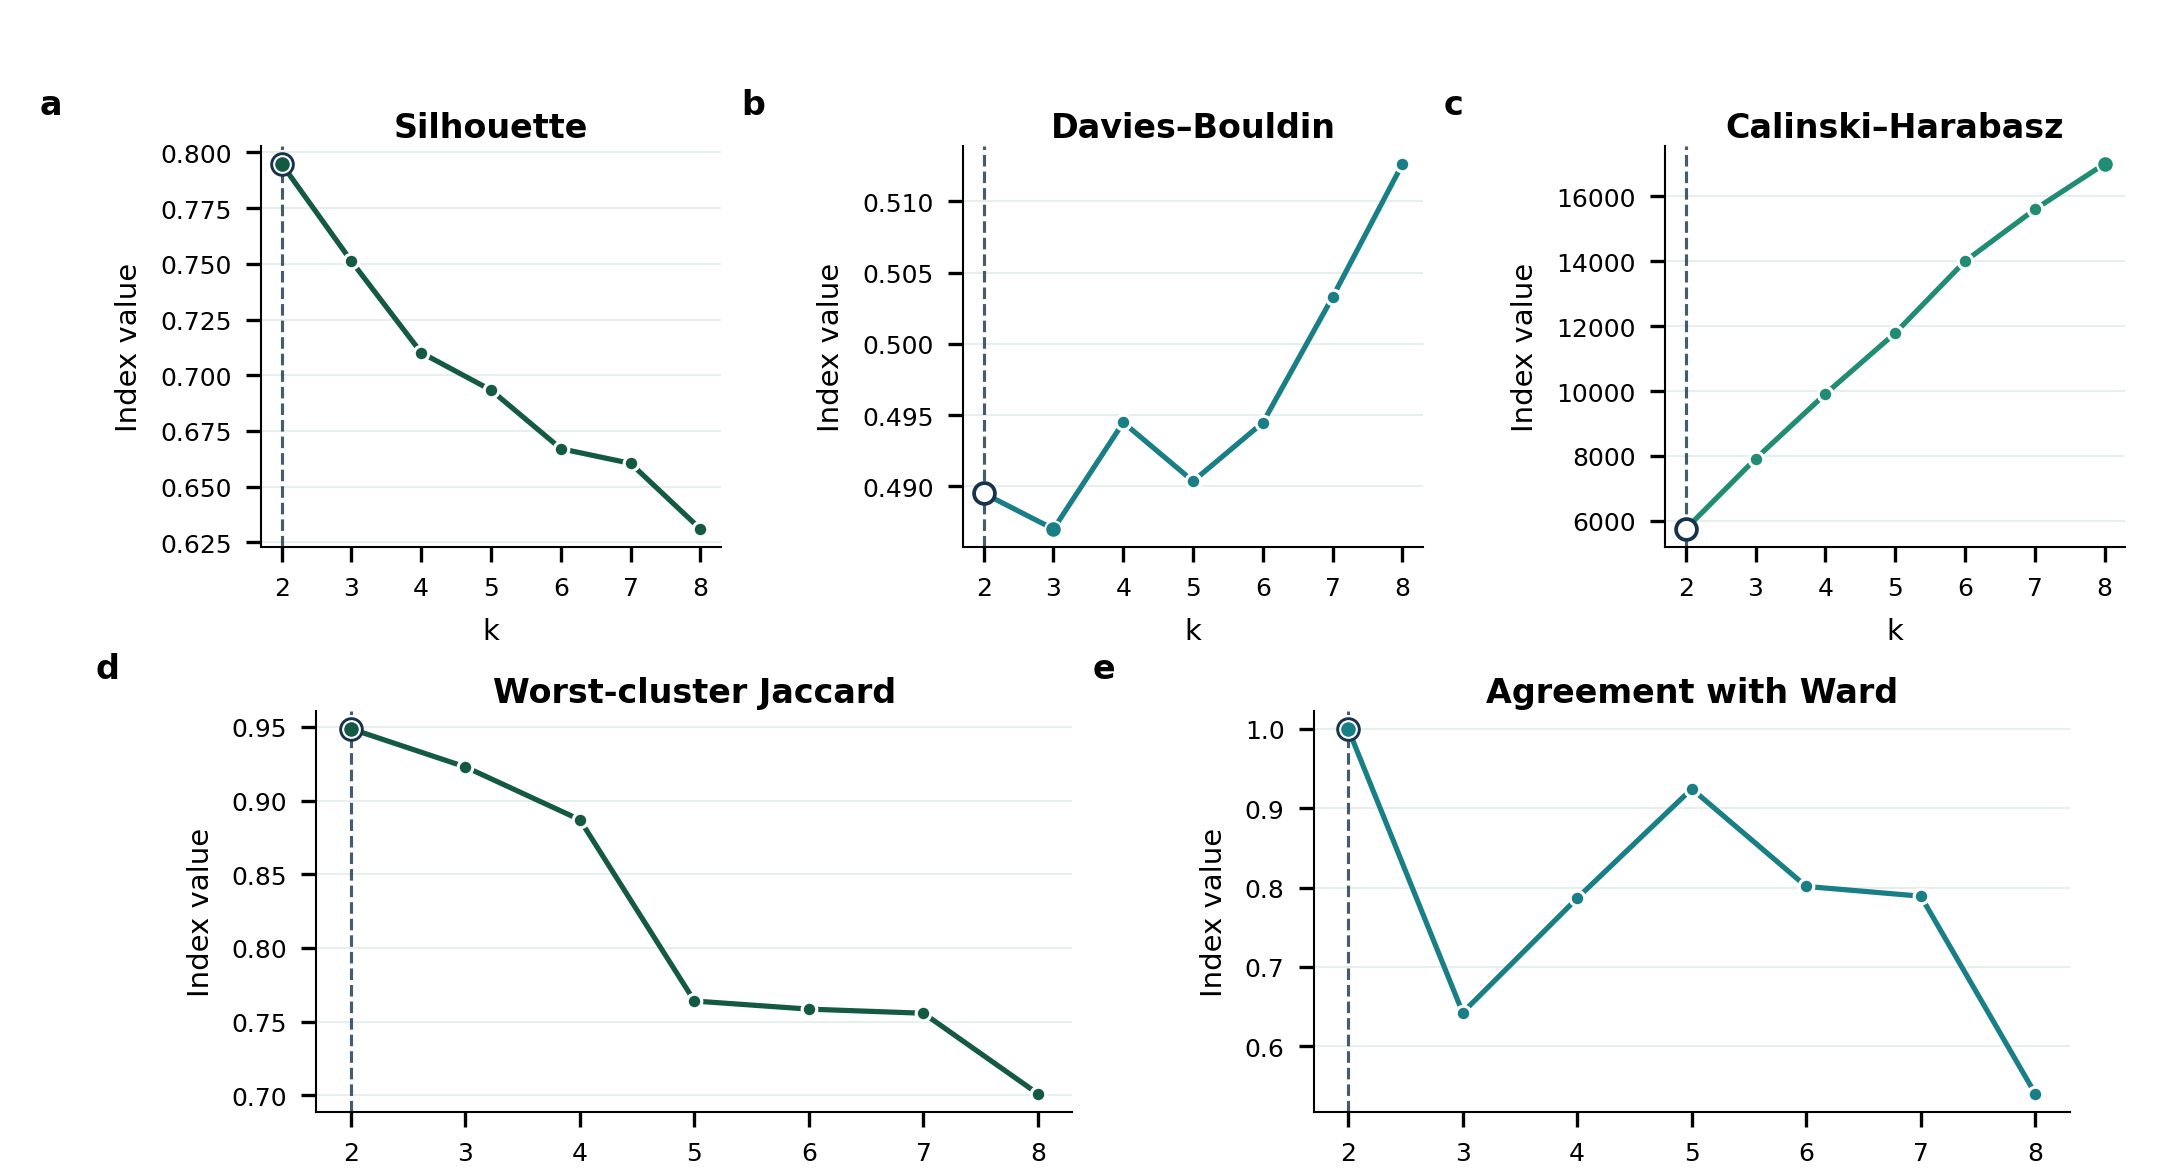

In [ ]:
# Figure 1. K-selection and validation diagnostics.
metric_specs = [
    ("a", "Silhouette", "Silhouette", "max", COLORS["forest"], 39, 34),
    ("b", "Davies-Bouldin", "Davies–Bouldin", "min", COLORS["teal"], 39, 34),
    ("c", "Calinski-Harabasz", "Calinski–Harabasz", "max", COLORS["green"], 39, 34),
    ("d", "Worst-cluster Jaccard", "Worst-cluster Jaccard", "max", COLORS["forest"], 64, 34),
    ("e", "ARI vs Ward", "Agreement with Ward", "max", COLORS["teal"], 64, 34)
]

mp1 = cns.multipanel(max_width=183, unit="mm")
fig1_axes = []

for letter, metric, title, direction, color, panel_width, panel_height in metric_specs:
    source = selection if metric in selection.columns else validation
    plot_data = source[["k", metric]].rename(columns={metric: "value"}).copy()
    ax = add_cns_panel(mp1, letter, panel_width, panel_height)
    cns.lineplot(
        data=plot_data,
        x="k",
        y="value",
        color=color,
        marker="o",
        markersize=3.5,
        linewidth=1.25,
        errorbar=None,
        ax=ax
    )
    ax.axvline(SELECTED_K, color=COLORS["navy"], linestyle="--", linewidth=0.75, alpha=0.8)
    selected_value = float(plot_data.loc[plot_data["k"] == SELECTED_K, "value"].iloc[0])
    ax.scatter(
        [SELECTED_K], [selected_value],
        s=25, facecolors="white", edgecolors=COLORS["navy"],
        linewidths=0.9, zorder=5
    )
    best_idx = int(
        np.argmax(plot_data["value"].to_numpy())
        if direction == "max"
        else np.argmin(plot_data["value"].to_numpy())
    )
    best_row = plot_data.iloc[best_idx]
    ax.scatter(
        [best_row["k"]], [best_row["value"]],
        s=16, color=color, edgecolors="white", linewidths=0.5, zorder=6
    )
    ax.set_title(title, pad=2)
    ax.set_xlabel("k")
    ax.set_ylabel("Index value")
    ax.set_xticks(range(2, 9))
    ax.grid(axis="y", color=COLORS["grid"], linewidth=0.45)
    ax.set_axisbelow(True)
    fig1_axes.append(ax)

fig1 = fig1_axes[0].figure
export_cns_figure(fig1, "figure1_k_selection")

**Figure 1 | The k = 2 solution is the only candidate meeting all three stated screening criteria.** a–c, Internal indices for k = 2–8; d, worst-cluster Jaccard across 50 firm-level bootstrap samples; e, adjusted Rand index (ARI) against Ward clustering. The dashed vertical line and open marker identify the selected k = 2 solution; filled markers identify each metric's optimum. The screening decision is reported separately in Table 3.

### Results from the k-selection checks

The highest Silhouette is at **k = 2 (.795)**. Davies-Bouldin is marginally lower at **k = 3 (.487 vs .490 at k = 2)**, while Calinski-Harabasz increases as k increases and does not identify a clear stopping point.

For k = 2, the worst-cluster bootstrap Jaccard is **.949** and ARI with Ward is **1.000**. k = 3 and k = 4 also have Jaccard above .85, but their Ward ARIs are .643 and .787. Under the stated .90 Ward cutoff, k = 2 is the only passing solution.

The sensitivity table shows that **the selected smallest k remains 2** when the Ward cutoff is varied from .60 to .90, although k = 3 and k = 4 become additional eligible alternatives at more relaxed cutoffs. This is a transparent screening decision, not proof of two naturally separated populations.

## 6. Main k = 2 profiles and secondary k = 3 comparison

The main labels are assigned by ordering the two K-Means centroids from higher to lower Working-capacity share. In the project data dictionary, **Working capacity** represents monetized damage to human health (including pathways such as climate, air pollution and toxicity), while **Water** represents impacts on drinking and irrigation water. **C2 is called Water-heavy only in a relative sense**: its Water share is much higher than C1's, but its mean Working-capacity share remains slightly larger than its mean Water share.

The k = 3 solution is retained only as a comparison. It shows whether the broad C2 group can be divided into more detailed segments. It does not replace the main k = 2 analysis.

In [ ]:
MAIN_K = SELECTED_K
assert MAIN_K == 2, f"The current cleaned data and screening rule selected k={MAIN_K}, not k=2."

km, raw_labels = models[MAIN_K]

# Label clusters by decreasing Working-capacity centroid.
order = np.argsort(-km.cluster_centers_[:, 0])
remap = {int(original): rank + 1 for rank, original in enumerate(order)}

cluster_names = {
    1: "Working-capacity dominant",
    2: "Water-heavy (relative)"
}

firm_features = firm_shares.copy()
firm_features["cluster_id"] = (
    pd.Series(raw_labels, index=firm_shares.index)
    .map(remap).astype(int)
)
firm_features["profile"] = firm_features.cluster_id.map(cluster_names)

profile = (
    firm_features.groupby(["cluster_id", "profile"], sort=True)[SAFEGUARDS]
    .mean().reset_index()
)
counts = firm_features.groupby("cluster_id").size()
profile["n_firms"] = profile.cluster_id.map(counts).astype(int)
profile["firm_pct"] = profile.n_firms / len(firm_features) * 100
profile["Working + Water (%)"] = (
    100 * (profile[SAFEGUARDS[0]] + profile[SAFEGUARDS[6]])
)
main_labels = firm_features.cluster_id.to_numpy()

# Display Working capacity and Water next to each other.
display_order = [
    SAFEGUARDS[0], SAFEGUARDS[6], SAFEGUARDS[1], SAFEGUARDS[2],
    SAFEGUARDS[3], SAFEGUARDS[4], SAFEGUARDS[5], SAFEGUARDS[7]
]
display_names = [
    "Working capacity", "Water", "Fish", "Crops",
    "Meat", "Biodiversity", "Abiotic", "Wood"
]

main_profile_table = profile[
    ["cluster_id", "profile", "n_firms", "firm_pct", *display_order]
].copy()
main_profile_table = main_profile_table.rename(
    columns=dict(zip(display_order, display_names))
)
for col in display_names:
    main_profile_table[col] *= 100

def format_share_pct(value):
    if 0 < value < 0.1:
        return "<0.1"
    return f"{value:.1f}"

print("Table 5. Mean share of absolute impact by main profile (%)")
display(
    main_profile_table.style.hide(axis="index").format({
        "n_firms": "{:,.0f}",
        "firm_pct": "{:.1f}%",
        **{name: format_share_pct for name in display_names}
    })
)

# Water-share distribution makes the within-profile spread visible.
water_values = firm_features[SAFEGUARDS[6]]
water_distribution = (
    pd.DataFrame({
        "Profile": firm_features["profile"],
        "Water share (%)": water_values.to_numpy() * 100
    })
    .groupby("Profile")["Water share (%)"]
    .quantile([.10, .25, .50, .75, .90])
    .unstack()
    .rename(columns={.10: "P10", .25: "P25", .50: "Median", .75: "P75", .90: "P90"})
    .reset_index()
)

print("Table 6. Distribution of firm-level Water shares within each k=2 profile (%)")
display(water_distribution.style.hide(axis="index").format({
    "P10": "{:.1f}", "P25": "{:.1f}", "Median": "{:.1f}",
    "P75": "{:.1f}", "P90": "{:.1f}"
}))

# Secondary k=3 solution, shown only to explain what the finer split adds.
km3, raw3 = models[3]
order3 = np.argsort(-km3.cluster_centers_[:, 0])
map3 = {int(original): rank + 1 for rank, original in enumerate(order3)}
labels3 = np.array([map3[int(label)] for label in raw3])

k3_names = {
    1: "Working-capacity dominant",
    2: "Intermediate",
    3: "Water-dominant"
}

k3_data = pd.DataFrame({
    "Secondary group": labels3,
    "Working capacity": X[:, 0],
    "Water": X[:, 6]
})
compare3 = (
    k3_data.groupby("Secondary group")
    .agg(
        Firms=("Working capacity", "size"),
        Working=("Working capacity", "mean"),
        Water=("Water", "mean")
    )
    .reset_index()
)
compare3["Profile"] = compare3["Secondary group"].map(k3_names)
compare3 = compare3[[
    "Secondary group", "Profile", "Firms", "Working", "Water"
]]

print("Table 7. Secondary k=3 solution (comparison only)")
display(compare3.style.hide(axis="index").format({
    "Firms": "{:,.0f}", "Working": "{:.1%}", "Water": "{:.1%}"
}))

k2_k3_overlap = pd.crosstab(
    pd.Series(main_labels, name="Main k=2"),
    pd.Series(labels3, name="Secondary k=3")
)
print("Firm overlap: how k=3 divides the two main k=2 profiles")
display(k2_k3_overlap)
print(
    f"ARI between k=2 and k=3 partitions = "
    f"{adjusted_rand_score(main_labels, labels3):.3f} "
    "(descriptive comparison; different numbers of clusters)."
)

Table 5. Mean share of absolute impact by main profile (%)


cluster_id,profile,n_firms,firm_pct,Working capacity,Water,Fish,Crops,Meat,Biodiversity,Abiotic,Wood
1,Working-capacity dominant,"2,202",88.6%,93.3,5.0,<0.1,1.2,0.3,<0.1,0.1,<0.1
2,Water-heavy (relative),283,11.4%,52.5,46.3,<0.1,0.7,0.2,<0.1,0.2,<0.1


Table 6. Distribution of firm-level Water shares within each k=2 profile (%)


Profile,P10,P25,Median,P75,P90
Water-heavy (relative),27.7,31.2,39.3,55.8,77.4
Working-capacity dominant,0.5,0.7,2.4,7.0,14.2


Table 7. Secondary k=3 solution (comparison only)


Secondary group,Profile,Firms,Working,Water
1,Working-capacity dominant,"2,002",94.8%,3.5%
2,Intermediate,386,71.8%,26.8%
3,Water-dominant,97,30.1%,68.9%


Firm overlap: how k=3 divides the two main k=2 profiles


Secondary k=3,1,2,3
Main k=2,,,
1,2002,200,0
2,0,186,97


ARI between k=2 and k=3 partitions = 0.627 (descriptive comparison; different numbers of clusters).


## 7. Profile composition and size

Figure 2 presents the mean safeguard composition, profile sizes, within-profile Water-share distributions, and the full firm-level Water-share distribution with a lower-tail view of the representation-dependent cut points. The exact profile counts and quantiles remain available in the separate tables.

figure2_profile_composition: 183.0 × 151.5 mm


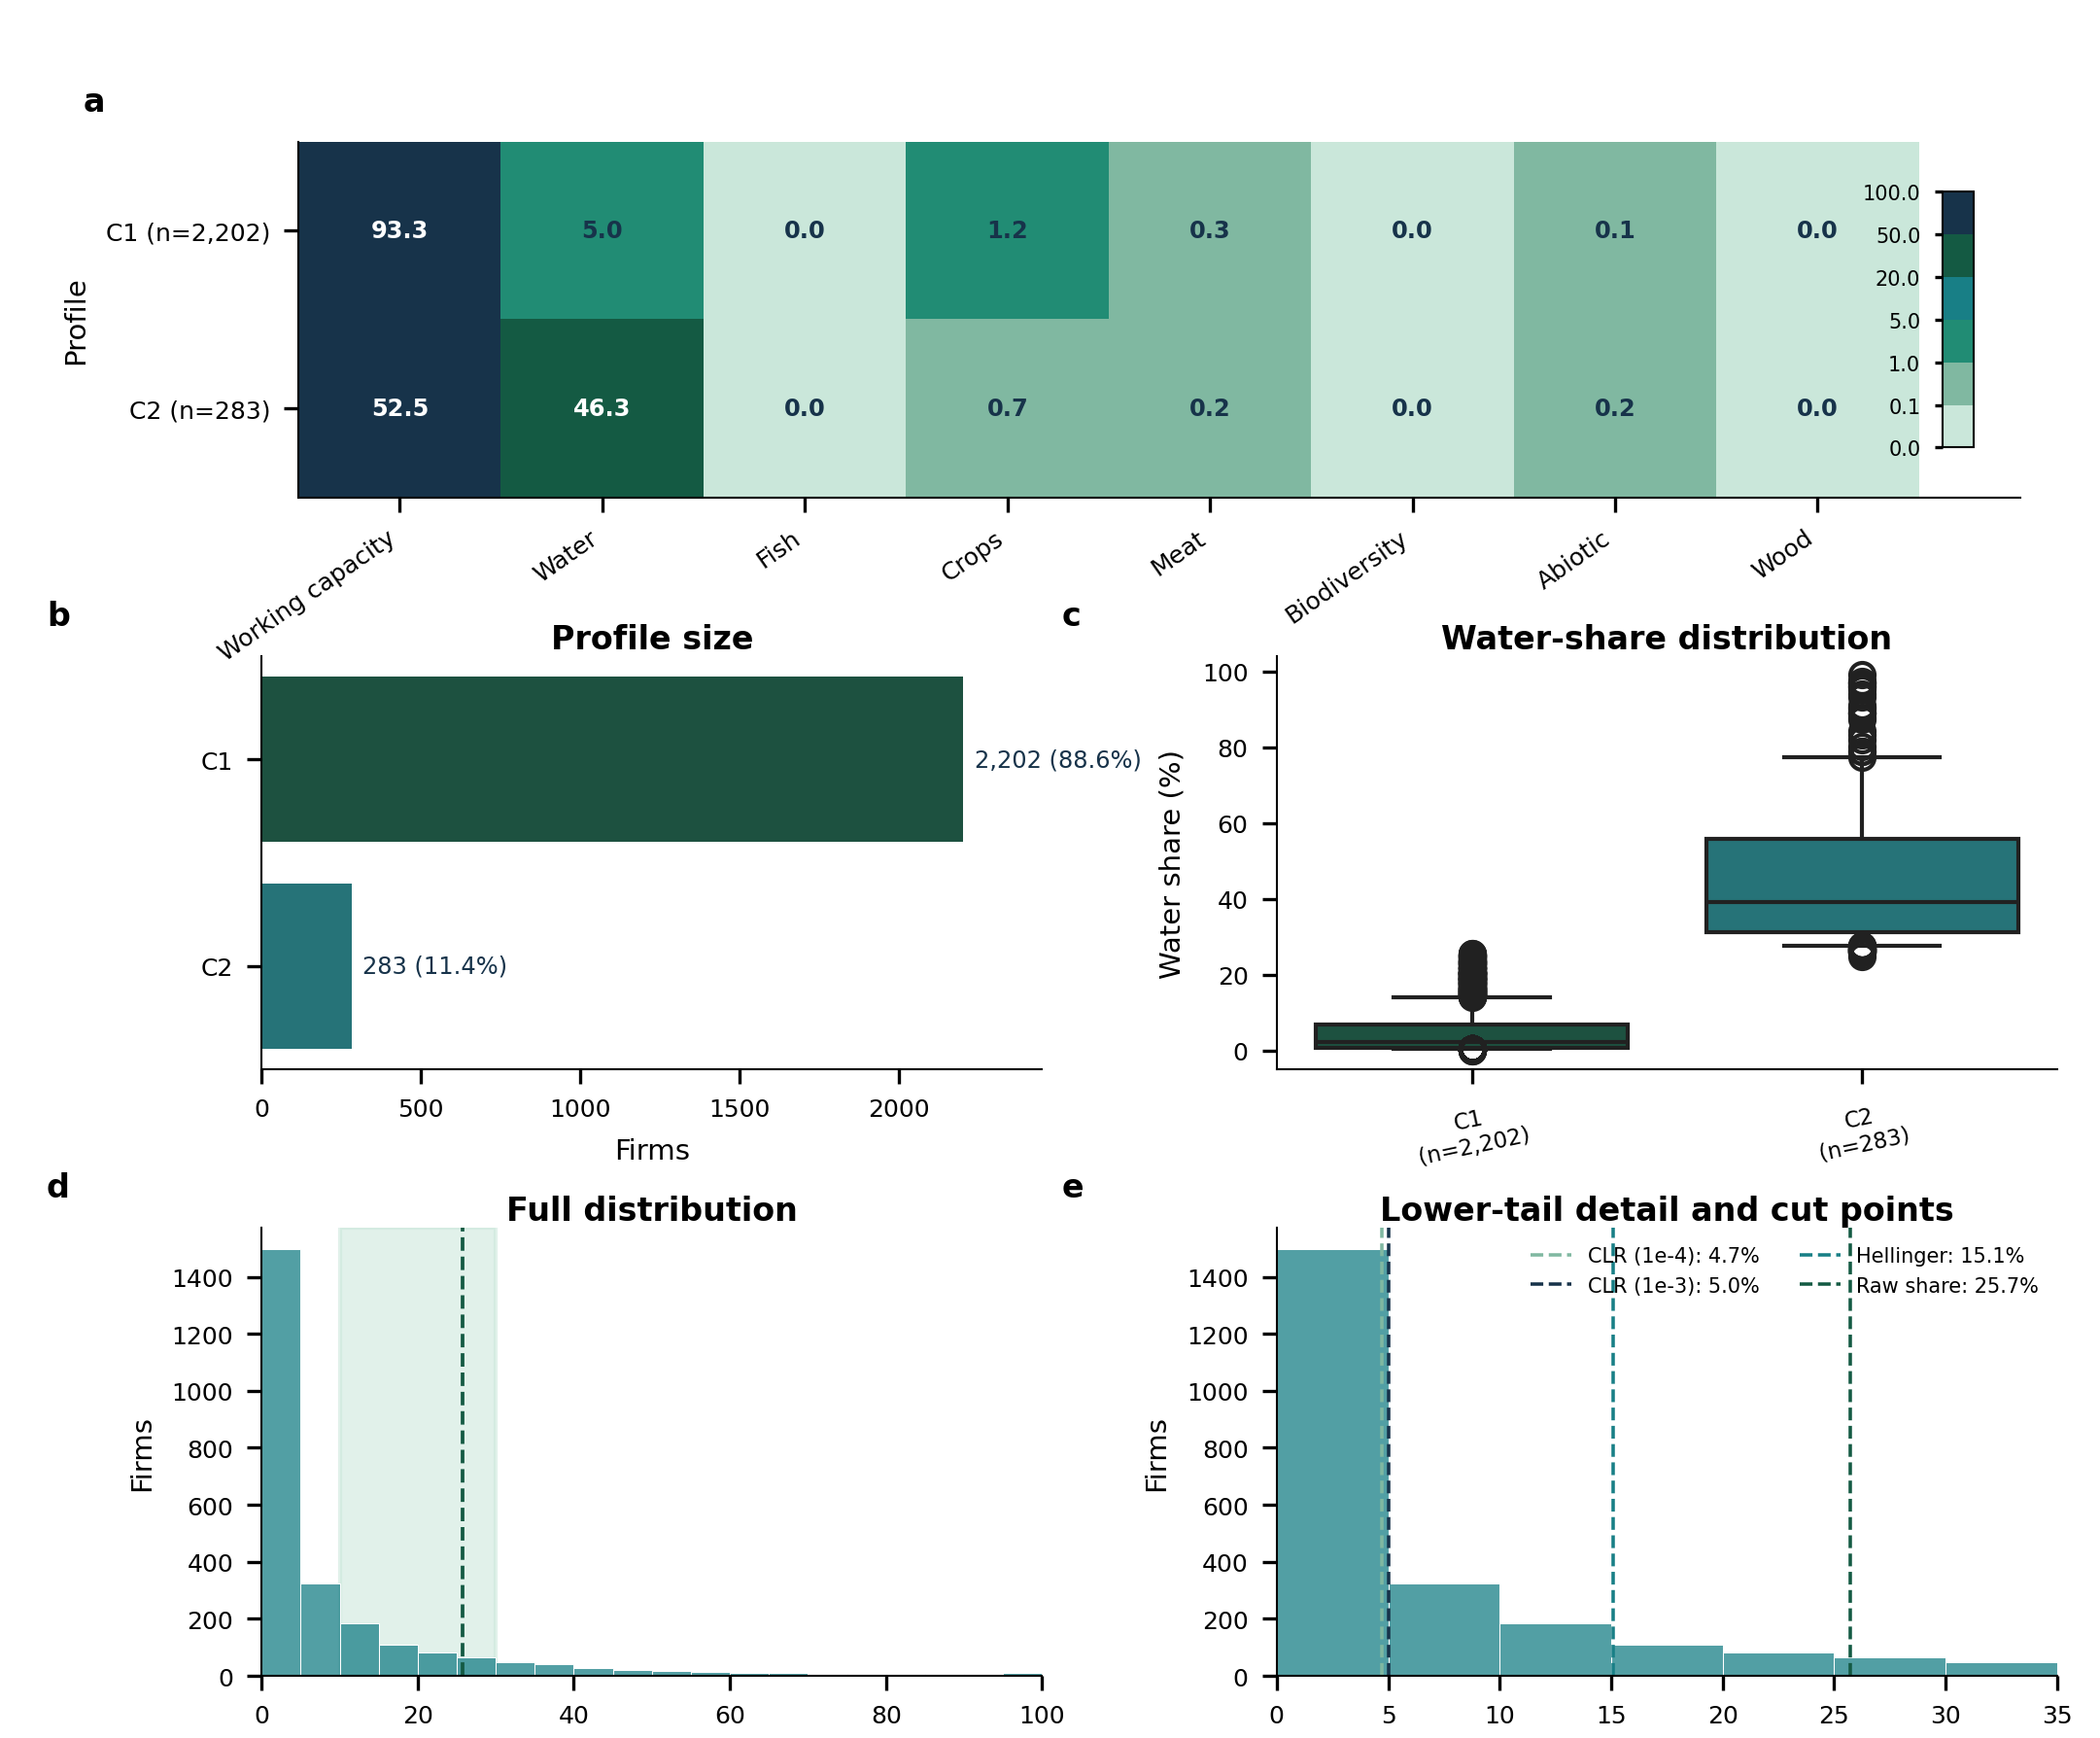

In [ ]:
# Figure 2. Profile composition and the continuous Water-share distribution.
matrix = profile.set_index("cluster_id")[display_order].to_numpy(dtype=float) * 100
profile_order = ["C1", "C2"]
profile_plot = profile.copy()
profile_plot["Profile"] = profile_plot["cluster_id"].map({1: "C1", 2: "C2"})
profile_palette = {
    profile_order[0]: COLORS["forest"],
    profile_order[1]: COLORS["teal"]
}

water_var = SAFEGUARDS[6]
water_plot = firm_features[["cluster_id", water_var]].copy()
water_plot["Profile"] = water_plot["cluster_id"].map({1: "C1", 2: "C2"})
water_plot["Water share (%)"] = water_plot[water_var] * 100
water_pct = water_plot["Water share (%)"].to_numpy(dtype=float)
water_hist_edges = np.arange(0, 105, 5)
transition_count = int(((water_pct >= 10) & (water_pct <= 30)).sum())
transition_pct = transition_count / len(water_pct) * 100

cutpoint_specs = [
    ("CLR (1e-4)", 4.7, COLORS["sage"]),
    ("CLR (1e-3)", 5.0, COLORS["navy"]),
    ("Hellinger", 15.1, COLORS["teal"]),
    ("Raw share", 25.7, COLORS["forest"])
]

mp2 = cns.multipanel(max_width=183, unit="mm")

# Panel a: heatmap. The discrete colour intervals are the original project bins.
ax2a = add_cns_panel(mp2, "a", 150, 31)
cmap = ListedColormap(HEATMAP_COLORS)
norm = BoundaryNorm(HEATMAP_BOUNDS, cmap.N)
im = ax2a.imshow(matrix, aspect="auto", cmap=cmap, norm=norm)
ax2a.set_xticks(np.arange(len(display_names)))
ax2a.set_xticklabels(display_names, rotation=35, ha="right", fontsize=6)
ax2a.set_xlim(-0.5, 8.0)
ax2a.set_yticks([0, 1])
ax2a.set_yticklabels(["C1 (n=2,202)", "C2 (n=283)"], fontsize=6)
ax2a.set_xlabel("")
ax2a.set_ylabel("Profile")
for r in range(matrix.shape[0]):
    for c in range(matrix.shape[1]):
        value = matrix[r, c]
        text_color = "white" if value >= 20 else COLORS["navy"]
        ax2a.text(c, r, f"{value:.1f}", ha="center", va="center",
                  fontsize=5.8, color=text_color, fontweight="bold")
cbar_ax = ax2a.inset_axes([0.955, 0.14, 0.018, 0.72])
cbar = ax2a.figure.colorbar(
    im, cax=cbar_ax, ticks=[0, 0.1, 1, 5, 20, 50, 100]
)
cbar.ax.yaxis.set_ticks_position("left")
cbar.ax.tick_params(labelsize=5.0, length=2)

# Panel b: profile sizes.
ax2b = add_cns_panel(mp2, "b", 68, 36)
cns.barplot(
    data=profile_plot,
    x="n_firms",
    y="Profile",
    order=profile_order,
    hue="Profile",
    hue_order=profile_order,
    palette=profile_palette,
    dodge=False,
    legend=False,
    errorbar=None,
    ax=ax2b
)
ax2b.set_title("Profile size", pad=2)
ax2b.set_xlabel("Firms")
ax2b.set_ylabel("")
ax2b.set_xlim(0, 2450)
for patch, (_, row) in zip(ax2b.patches, profile_plot.set_index("Profile").loc[profile_order].iterrows()):
    ax2b.text(
        patch.get_width() + 35,
        patch.get_y() + patch.get_height() / 2,
        f'{int(row["n_firms"]):,} ({row["firm_pct"]:.1f}%)',
        va="center", fontsize=5.8, color=COLORS["navy"]
    )

# Panel c: P10-P90 whiskers and P25-P75 boxes.
ax2c = add_cns_panel(mp2, "c", 68, 36)
cns.boxplot(
    data=water_plot,
    x="Profile",
    y="Water share (%)",
    order=profile_order,
    hue="Profile",
    hue_order=profile_order,
    palette=profile_palette,
    dodge=False,
    legend=False,
    whis=(10, 90),
    add_count=True,
    showoutliers=False,
    ax=ax2c
)
ax2c.set_title("Water-share distribution", pad=2)
ax2c.set_xlabel("")
ax2c.set_ylabel("Water share (%)")
ax2c.tick_params(axis="x", labelrotation=12, labelsize=5.5)

# Panel d: full Water-share distribution.
ax2d = add_cns_panel(mp2, "d", 68, 39)
ax2d.axvspan(10, 30, color=COLORS["mint"], alpha=0.55, zorder=0)
cns.histplot(
    data=water_plot,
    x="Water share (%)",
    bins=water_hist_edges,
    color=COLORS["teal"],
    edgecolor="white",
    linewidth=0.25,
    ax=ax2d
)
ax2d.axvline(25.7, color=COLORS["forest"], linestyle="--", linewidth=0.9)
ax2d.set_xlim(0, 100)
ax2d.set_title("Full distribution", pad=2)
ax2d.set_xlabel("Water share (%)")
ax2d.set_ylabel("Firms")

# Panel e: lower-tail view, where the representation-dependent cut points are readable.
ax2e = add_cns_panel(mp2, "e", 68, 39)
cns.histplot(
    data=water_plot,
    x="Water share (%)",
    bins=np.arange(0, 40, 5),
    color=COLORS["teal"],
    edgecolor="white",
    linewidth=0.25,
    ax=ax2e
)
for label, value, color in cutpoint_specs:
    ax2e.axvline(value, color=color, linestyle="--", linewidth=0.85, label=f"{label}: {value:.1f}%")
ax2e.set_xlim(0, 35)
ax2e.set_title("Lower-tail detail and cut points", pad=2)
ax2e.set_xlabel("Water share (%)")
ax2e.set_ylabel("Firms")
ax2e.legend(frameon=False, fontsize=5.0, ncol=2, loc="upper right")

fig2 = ax2a.figure
export_cns_figure(fig2, "figure2_profile_composition")

**Figure 2 | The two profiles differ mainly in Working capacity and Water, while firm-level Water shares form a broad distribution.** a, Mean safeguard composition by profile; colours use the original non-uniform share bins. b, Number and percentage of firms in each profile. c, Firm-level Water-share distribution (boxes, P25–P75; centre line, median; whiskers, P10–P90). d, Full Water-share distribution, with the descriptive 10–30% transition band. e, Lower-tail detail and approximate raw-share, Hellinger and CLR cut points. The transition band contains 440 firms (17.7%); it does not alter the k = 2 assignments.

**Results.** C1 contains 2,202 firms (88.6%) and C2 contains 283 (11.4%). Mean Working-capacity and Water shares are 93.3% and 5.0% in C1, compared with 52.5% and 46.3% in C2. C2 is a broad group: its firm-level Water-share P10 to P90 range is approximately 27.7% to 77.4%, so its mean should not be read as a uniform company type. The k = 3 comparison splits C2 into 186 intermediate and 97 Water-dominant firms.

## 8. Compositional structure: PCA, centroid separation and CLR sensitivity

The eight shares are compositional because they sum to one. This creates mathematical dependence: when two components dominate the total, their shares can move in opposite directions even without a causal relationship.

PCA is therefore reported only as a **description of the raw-share geometry**, not as independent proof of a natural one-dimensional structure. We also calculate how much of the K-Means centroid gap is contributed by each subject under the raw Euclidean distance.

Compositional-data analysis commonly uses log-ratios (Aitchison, 1982). As a sensitivity check, we repeat k = 2 K-Means after a centred log-ratio (CLR) transformation. CLR requires strictly positive values, so small pseudocounts are added and the composition is re-closed. Different pseudocounts are tested because zero replacement can affect the result.

In [ ]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(X)

pc1_corr_work = np.corrcoef(pcs[:, 0], X[:, 0])[0, 1]
pc1_corr_water = np.corrcoef(pcs[:, 0], X[:, 6])[0, 1]
working_water = (X[:, 0] + X[:, 6]) * 100

pca_summary = pd.DataFrame({
    "Diagnostic": [
        "Mean Working capacity + Water share",
        "Median Working capacity + Water share",
        "PC1 variance explained",
        "PC2 variance explained",
        "Correlation of PC1 with Working capacity",
        "Correlation of PC1 with Water"
    ],
    "Result": [
        f"{working_water.mean():.2f}%",
        f"{np.median(working_water):.2f}%",
        f"{pca.explained_variance_ratio_[0]:.2%}",
        f"{pca.explained_variance_ratio_[1]:.2%}",
        f"{pc1_corr_work:+.4f}",
        f"{pc1_corr_water:+.4f}"
    ]
})

print("Table 8. PCA summary for the raw firm-level shares")
display(pca_summary.style.hide(axis="index"))

# Quantify which features separate the two raw-share K-Means centroids.
ordered_centroids = km.cluster_centers_[order]
squared_gap = (ordered_centroids[0] - ordered_centroids[1]) ** 2
centroid_gap = pd.DataFrame({
    "Safeguard": SHORT_NAMES,
    "Absolute centroid difference (pp)": np.abs(
        ordered_centroids[0] - ordered_centroids[1]
    ) * 100,
    "Share of squared centroid gap (%)": (
        squared_gap / squared_gap.sum() * 100
    )
}).sort_values("Share of squared centroid gap (%)", ascending=False)

print("Table 9. Contribution to the k=2 centroid gap under raw Euclidean distance")
def format_gap_share(value):
    if 0 < value < 0.001:
        return "<0.001"
    return f"{value:.3f}"

display(centroid_gap.style.hide(axis="index").format({
    "Absolute centroid difference (pp)": "{:.3f}",
    "Share of squared centroid gap (%)": format_gap_share
}))

# CLR sensitivity: add a small pseudocount, re-close each composition,
# apply CLR, then fit K-Means with the same k.
clr_rows = []
for pseudocount in [1e-6, 1e-4, 1e-3]:
    positive = X + pseudocount
    closed = positive / positive.sum(axis=1, keepdims=True)
    log_closed = np.log(closed)
    clr_X = log_closed - log_closed.mean(axis=1, keepdims=True)

    clr_labels = KMeans(
        n_clusters=MAIN_K,
        random_state=42,
        n_init=30,
        max_iter=500
    ).fit_predict(clr_X)

    clr_rows.append({
        "Pseudocount": pseudocount,
        "ARI vs raw-share k=2": adjusted_rand_score(main_labels, clr_labels),
        "Smallest CLR cluster": int(np.bincount(clr_labels).min()),
        "Largest CLR cluster": int(np.bincount(clr_labels).max())
    })

clr_sensitivity = pd.DataFrame(clr_rows)

print("Table 10. CLR sensitivity to zero-replacement pseudocount")
display(clr_sensitivity.style.hide(axis="index").format({
    "Pseudocount": "{:.0e}",
    "ARI vs raw-share k=2": "{:.3f}",
    "Smallest CLR cluster": "{:,.0f}",
    "Largest CLR cluster": "{:,.0f}"
}))

print(
    f"Raw-share centroid separation: Working capacity + Water account for "
    f"{centroid_gap.loc[centroid_gap.Safeguard.isin(['Working capacity','Water']), 'Share of squared centroid gap (%)'].sum():.2f}% "
    "of the squared distance between the two centroids."
)

Table 8. PCA summary for the raw firm-level shares


Diagnostic,Result
Mean Working capacity + Water share,98.37%
Median Working capacity + Water share,98.38%
PC1 variance explained,99.71%
PC2 variance explained,0.28%
Correlation of PC1 with Working capacity,-0.9995
Correlation of PC1 with Water,+0.9995


Table 9. Contribution to the k=2 centroid gap under raw Euclidean distance


Safeguard,Absolute centroid difference (pp),Share of squared centroid gap (%)
Water,41.297,50.641
Working capacity,40.767,49.350
Crops,0.538,0.009
Meat,0.128,<0.001
Abiotic,0.114,<0.001
Biodiversity,0.023,<0.001
Wood,0.005,<0.001
Fish,0.005,<0.001


Table 10. CLR sensitivity to zero-replacement pseudocount


Pseudocount,ARI vs raw-share k=2,Smallest CLR cluster,Largest CLR cluster
1e-06,-0.002,"1,123","1,362"
1e-04,0.154,"1,011","1,474"
1e-03,0.163,993,"1,492"


Raw-share centroid separation: Working capacity + Water account for 99.99% of the squared distance between the two centroids.


**Results.** Working capacity and Water together account for 98.37% of the average absolute-impact composition. PC1 explains 99.71% of raw-share variance, and its correlations with the two largest shares are both above .999 in absolute value. The two subjects also account for virtually all of the raw K-Means centroid gap. These patterns describe the raw-share geometry and are partly expected from the fixed-sum constraint. CLR gives low agreement with the raw-share partition across the tested pseudocounts, so the two-profile result is **sensitive to how compositional data are represented**.

## 9. Industry analysis: which sectors are represented in each profile?

Industry is attached **after** clustering, so it cannot create the profiles. Each company receives one EXIOBASE industry label. The notebook first checks whether a company's industry changes across years; if it does, the most frequent non-missing label is used.

Two questions are kept separate:

1. **Composition by count:** which industries contain the most companies in each profile?
2. **Over- or under-representation:** is an industry more or less common in a profile than its share of the full sample would suggest?

Lift measures relative representation, not environmental damage. A lift above 1 means over-representation; below 1 means under-representation.

In [ ]:
def robust_mode(series):
    modes = series.dropna().mode()
    return modes.iloc[0] if not modes.empty else "Unknown"

firm_industry_unique = (
    clean.groupby("company_name")["industry_exiobase"]
    .nunique(dropna=True)
)
firms_changing_industry = int((firm_industry_unique > 1).sum())

if firms_changing_industry:
    print(
        f"Note: {firms_changing_industry} firms have more than one observed "
        "industry; the most frequent non-missing label is used."
    )
else:
    print(
        "All firms with a non-missing industry have one observed EXIOBASE "
        "industry across years."
    )

firm_meta = clean.groupby("company_name", sort=False).agg(
    industry_exiobase=("industry_exiobase", robust_mode),
    observed_years=("year", "nunique")
)

assignments = (
    firm_meta.join(firm_features[["cluster_id", "profile"]], how="inner")
    .reset_index()
)

assert len(assignments) == len(firm_features)
assert assignments["company_name"].is_unique

obs = pd.crosstab(
    assignments["industry_exiobase"].fillna("Unknown"),
    assignments["cluster_id"]
).reindex(columns=[1, 2], fill_value=0)

industry_total = obs.sum(axis=1)
cluster_total = obs.sum(axis=0)
N = int(obs.to_numpy().sum())

lift = (
    obs.div(cluster_total, axis=1)
    .div(industry_total / N, axis=0)
)

# Counts and lift are shown together so that large sectors are not
# mistaken for sectors that are unusually concentrated in a profile.
top_count_rows = []
for cid in obs.columns:
    for industry, n in obs[cid].nlargest(5).items():
        top_count_rows.append({
            "Profile": f"C{cid}: {cluster_names[cid]}",
            "Industry": industry,
            "Firms in profile": int(n),
            "Share of profile (%)": 100 * n / cluster_total[cid],
            "Industry total": int(industry_total.loc[industry]),
            "Lift": float(lift.loc[industry, cid])
        })

top_industry_counts = pd.DataFrame(top_count_rows)

print(
    f"Industry sample: {N:,} firms across {len(obs)} categories; "
    f"firms with changing industry={firms_changing_industry}."
)
print("Table 11. Most common industries by profile, with lift")
display(
    top_industry_counts.style.hide(axis="index").format({
        "Firms in profile": "{:,.0f}",
        "Share of profile (%)": "{:.1f}",
        "Industry total": "{:,.0f}",
        "Lift": "{:.2f}×"
    })
)

All firms with a non-missing industry have one observed EXIOBASE industry across years.


Industry sample: 2,485 firms across 56 categories; firms with changing industry=0.
Table 11. Most common industries by profile, with lift


Profile,Industry,Firms in profile,Share of profile (%),Industry total,Lift
C1: Working-capacity dominant,"Financial intermediation, except insurance and pension funding (65)",250,11.4,291,0.97×
C1: Working-capacity dominant,Manufacture of electrical machinery and apparatus n.e.c. (31),117,5.3,121,1.09×
C1: Working-capacity dominant,Real estate activities (70),106,4.8,130,0.92×
C1: Working-capacity dominant,"Retail trade, except of motor vehicles and motorcycles; repair of personal and household goods (52)",104,4.7,110,1.07×
C1: Working-capacity dominant,Construction (45),99,4.5,107,1.04×
C2: Water-heavy (relative),"Financial intermediation, except insurance and pension funding (65)",41,14.5,291,1.24×
C2: Water-heavy (relative),Real estate activities (70),24,8.5,130,1.62×
C2: Water-heavy (relative),Processing of Food products nec,20,7.1,96,1.83×
C2: Water-heavy (relative),Manufacture of beverages,19,6.7,40,4.17×
C2: Water-heavy (relative),Quarrying of sand and clay,17,6.0,71,2.10×


### 9.1 Industry-level Fisher tests and false-discovery-rate adjustment

For **k = 2**, the C1 and C2 cells for the same industry are not two independent tests. They are two sides of the same 2 × 2 comparison: that industry versus all other industries, crossed with C2 versus C1. The notebook therefore runs **one Fisher exact test per industry**, giving 56 tests, and applies Benjamini-Hochberg FDR across those 56 p-values (Benjamini & Hochberg, 1995).

Adjusted residuals show direction: a positive C2 residual means more firms in C2 than expected under independence; a negative value means fewer. Fisher tests use all industries, including sparse ones. The minimum industry-size rule is used only to keep the displayed table readable, not to determine statistical significance.

In [ ]:
MIN_INDUSTRY_FIRMS = 10
FDR_ALPHA = 0.05

expected = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / N
residuals = (
    obs.to_numpy(dtype=float) - expected
) / np.sqrt(
    expected
    * (1 - obs.sum(axis=1).to_numpy()[:, None] / N)
    * (1 - obs.sum(axis=0).to_numpy()[None, :] / N)
)

# One exact 2x2 test per industry, not one test for each of the two profile cells.
industry_test_rows = []

for i, industry in enumerate(obs.index):
    c2_in = int(obs.loc[industry, 2])
    c1_in = int(obs.loc[industry, 1])
    c2_out = int(cluster_total[2] - c2_in)
    c1_out = int(cluster_total[1] - c1_in)

    odds_ratio, p_value = fisher_exact(
        [[c2_in, c1_in], [c2_out, c1_out]],
        alternative="two-sided"
    )

    industry_test_rows.append({
        "Industry": industry,
        "Industry firms (N)": int(industry_total.loc[industry]),
        "C2 firms": c2_in,
        "C1 firms": c1_in,
        "C2 lift": float(lift.loc[industry, 2]),
        "C2 adjusted residual": float(residuals[i, 1]),
        "Odds ratio": float(odds_ratio),
        "Fisher p": float(p_value)
    })

industry_tests = pd.DataFrame(industry_test_rows)
industry_tests["BH-FDR q"] = multipletests(
    industry_tests["Fisher p"].to_numpy(),
    method="fdr_bh"
)[1]

industry_tests["Direction in C2"] = np.where(
    industry_tests["C2 adjusted residual"] > 0,
    "Over-represented",
    "Under-represented"
)
industry_tests["FDR significant"] = industry_tests["BH-FDR q"] < FDR_ALPHA

significant_industries = (
    industry_tests[
        industry_tests["FDR significant"]
        & (industry_tests["Industry firms (N)"] >= MIN_INDUSTRY_FIRMS)
    ]
    .sort_values("BH-FDR q")
)

print(
    f"Fisher tests: {len(industry_tests)} unique industry tests; "
    f"{int(industry_tests['FDR significant'].sum())} pass BH-FDR q < .05."
)
print(
    f"Expected counts below 5: {(expected < 5).sum()} of {expected.size} "
    "industry-profile cells."
)
print("Table 12. Industries with FDR-significant differences and N ≥ 10")
display(
    significant_industries[[
        "Industry", "Industry firms (N)", "C2 firms", "C1 firms",
        "Direction in C2", "C2 lift", "C2 adjusted residual",
        "Fisher p", "BH-FDR q"
    ]].style.hide(axis="index").format({
        "Industry firms (N)": "{:,.0f}",
        "C2 firms": "{:,.0f}",
        "C1 firms": "{:,.0f}",
        "C2 lift": "{:.2f}×",
        "C2 adjusted residual": "{:+.2f}",
        "Fisher p": "{:.3g}",
        "BH-FDR q": "{:.3g}"
    })
)

Fisher tests: 56 unique industry tests; 5 pass BH-FDR q < .05.
Expected counts below 5: 41 of 112 industry-profile cells.
Table 12. Industries with FDR-significant differences and N ≥ 10


Industry,Industry firms (N),C2 firms,C1 firms,Direction in C2,C2 lift,C2 adjusted residual,Fisher p,BH-FDR q
Manufacture of beverages,40,19,21,Over-represented,4.17×,+7.25,9.41e-09,5.27e-07
Manufacture of electrical machinery and apparatus n.e.c. (31),121,4,117,Under-represented,0.29×,-2.87,0.00187,0.0239
"Manufacture of fabricated metal products, except machinery and equipment (28)",64,0,64,Under-represented,0.00×,-2.91,0.000919,0.0239
Post and telecommunications (64),92,2,90,Under-represented,0.19×,-2.84,0.00214,0.0239
Quarrying of sand and clay,71,17,54,Over-represented,2.10×,+3.38,0.00204,0.0239


### Figure 3. Industry representation in the Water-heavy profile

The figure shows only the five industries that remain significant after BH-FDR correction. Global association statistics are reported separately in Table 13.

figure3_industry_representation: 183.0 × 82.0 mm


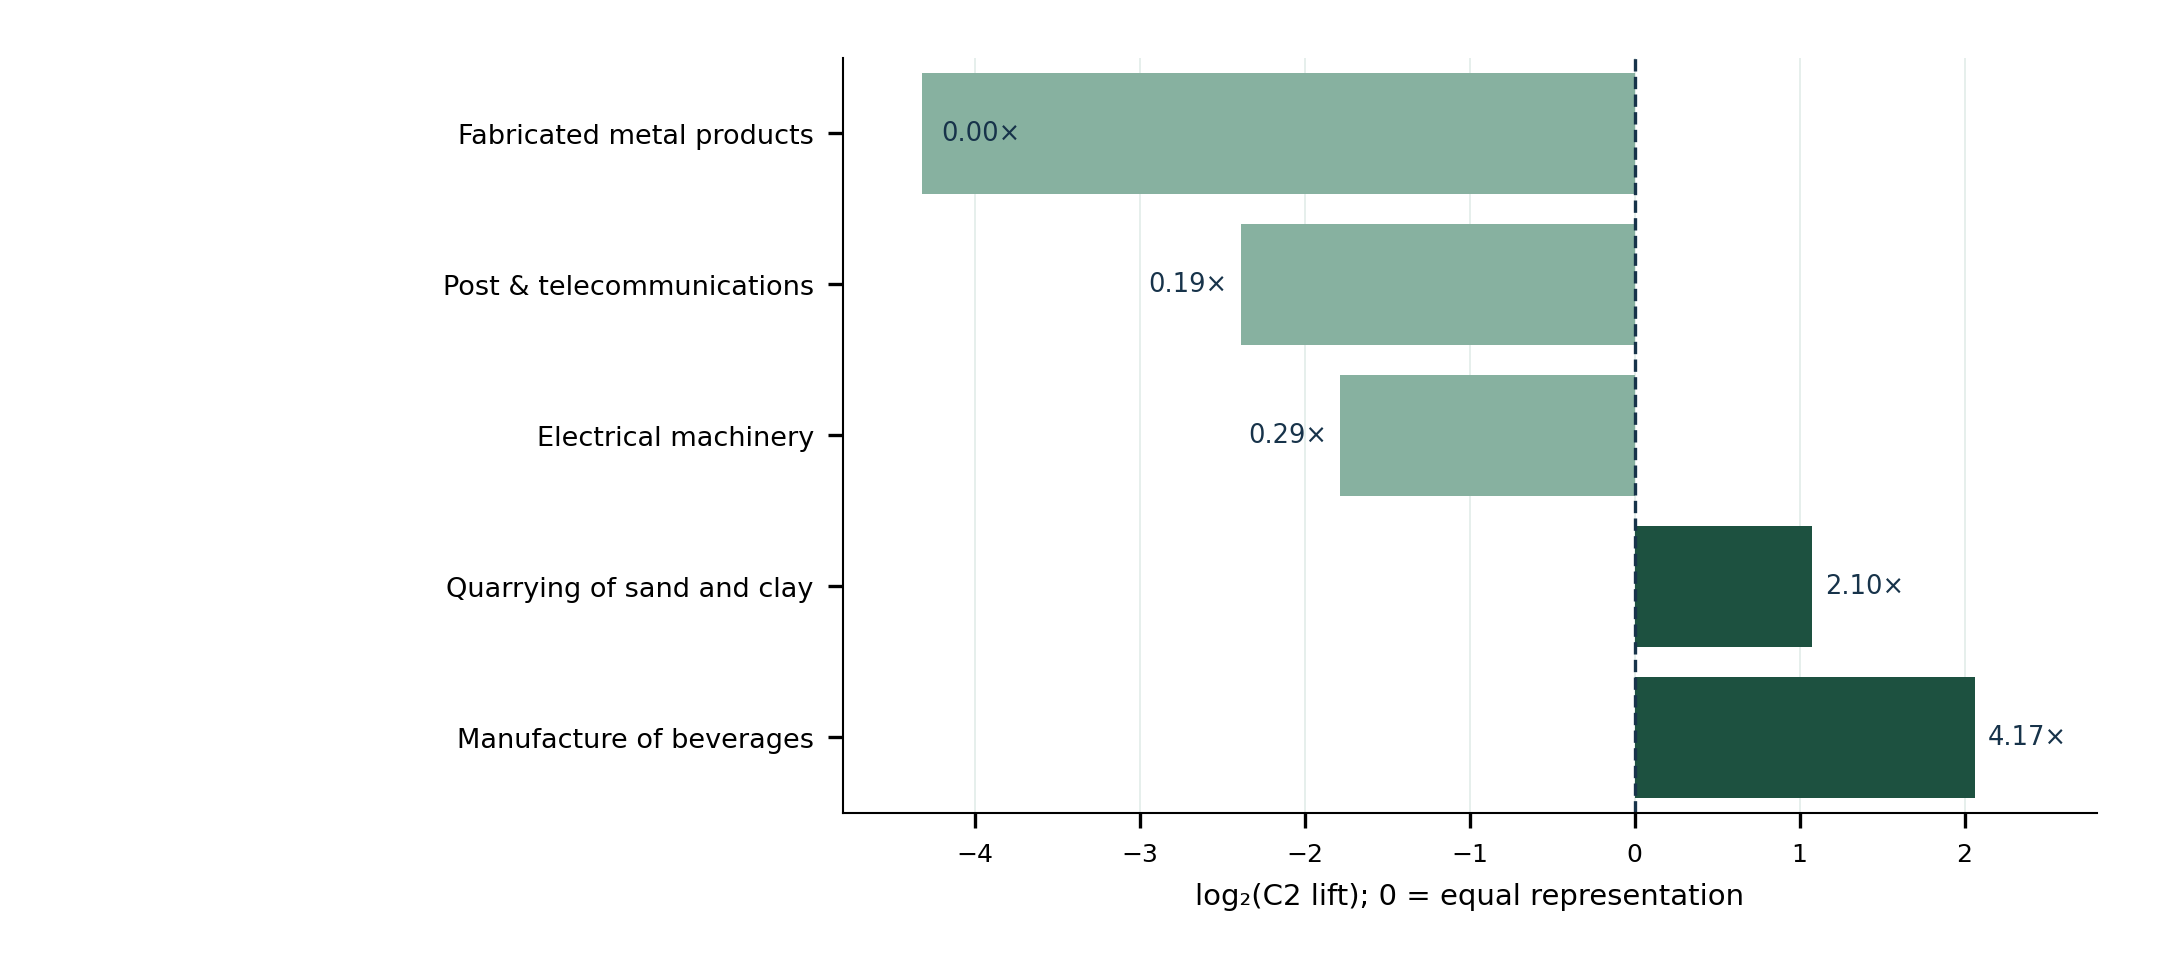

In [ ]:
# Figure 3. Industries with FDR-significant over- or under-representation in C2.
industry_short_names = {
    "Manufacture of beverages": "Manufacture of beverages",
    "Quarrying of sand and clay": "Quarrying of sand and clay",
    "Manufacture of electrical machinery and apparatus n.e.c. (31)": "Electrical machinery",
    "Post and telecommunications (64)": "Post & telecommunications",
    "Manufacture of fabricated metal products, except machinery and equipment (28)": "Fabricated metal products"
}
industry_plot = significant_industries.copy()
industry_plot["Industry short"] = industry_plot["Industry"].map(
    lambda value: industry_short_names.get(value, value)
)
industry_plot["log2 lift"] = np.log2(industry_plot["C2 lift"].clip(lower=0.05))
industry_plot = industry_plot.sort_values("log2 lift", ascending=True)
industry_order = industry_plot["Industry short"].tolist()
industry_palette = {
    row["Industry short"]: (
        COLORS["forest"] if row["C2 lift"] > 1 else COLORS["sage"]
    )
    for _, row in industry_plot.iterrows()
}

fig3 = cns.figure(
    width=183,
    height=82,
    color_cycle=PROJECT_PALETTE,
    unit="mm"
)
ax3 = cns.barplot(
    data=industry_plot,
    x="log2 lift",
    y="Industry short",
    hue="Industry short",
    hue_order=industry_order,
    order=industry_order,
    palette=industry_palette,
    dodge=False,
    legend=False,
    errorbar=None,
    orient="y"
)
ax3.axvline(0, color=COLORS["navy"], linestyle="--", linewidth=0.8)
ax3.set_xlim(-4.8, 2.8)
ax3.set_xlabel("log₂(C2 lift); 0 = equal representation")
ax3.set_ylabel("")
ax3.set_yticks(np.arange(len(industry_order)))
ax3.set_yticklabels(industry_order, fontsize=6.5)
ax3.figure.subplots_adjust(left=0.39, right=0.97, top=0.94, bottom=0.16)
ax3.grid(axis="x", color=COLORS["grid"], linewidth=0.45)
ax3.set_axisbelow(True)
legend_handles = [
    Patch(facecolor=COLORS["forest"], label="Over-represented in C2"),
    Patch(facecolor=COLORS["sage"], label="Under-represented in C2")
]
# Direction is encoded by the zero reference: positive = over-represented; negative = under-represented.

for patch, (_, row) in zip(ax3.patches, industry_plot.iterrows()):
    endpoint = float(row["log2 lift"])
    if endpoint >= 0:
        x_text, ha = endpoint + 0.08, "left"
    elif float(row["C2 lift"]) <= 0.05:
        x_text, ha = endpoint + 0.12, "left"
    else:
        x_text, ha = endpoint - 0.08, "right"
    ax3.text(
        x_text,
        patch.get_y() + patch.get_height() / 2,
        f'{row["C2 lift"]:.2f}×',
        ha=ha, va="center", fontsize=6.2, color=COLORS["navy"]
    )

export_cns_figure(fig3, "figure3_industry_representation")

**Figure 3 | Five industries are over- or under-represented in C2 after BH-FDR correction.** Bars show log₂(C2 lift), with zero indicating equal representation. Forest denotes over-representation and sage denotes under-representation. Lift describes relative representation, not environmental damage. The Fisher tests, C2 counts and adjusted q-values are reported in the industry results table; the global industry-profile association is reported separately in Table 13.

**Results.** Five industries meet BH-FDR q < .05 after testing 56 unique industry comparisons: two are over-represented in C2 (Beverages and Quarrying of sand and clay), while three are under-represented (Electrical machinery, Fabricated metal products, and Post and telecommunications). The C1 lift is mechanically constrained by C1's large sample share and is not used as the main enrichment display.

### 9.2 Overall association between industry and profile

The global chi-square statistic tests whether industry and profile membership are associated. Because many expected cell counts are below five, the notebook uses a firm-level permutation test that shuffles profile labels while keeping profile totals fixed.

Cramér's V summarizes association strength. The bias-corrected version is reported because the table has many industry categories relative to the sample size (Bergsma, 2013). To check whether industry-level imputation may influence the association, the full sample is compared with a separately fitted k = 2 solution among firms with no more than 5% imputed firm-year data. Both samples are reported together in **Table 13**. This is a table because readers need the exact test statistics and association measures. Neither the p-value nor Cramér's V establishes that industry causes a profile.

In [ ]:
chi2, asymptotic_p, dof, expected = chi2_contingency(obs, correction=False)
full_expected = expected.copy()

# Raw and Bergsma bias-corrected Cramer's V for the full sample.
n_rows, n_cols = obs.shape
phi2 = chi2 / N
cramers_v = np.sqrt(
    chi2 / (N * min(n_rows - 1, n_cols - 1))
)

phi2_corrected = max(
    0.0,
    phi2 - ((n_cols - 1) * (n_rows - 1)) / (N - 1)
)
rows_corrected = n_rows - ((n_rows - 1) ** 2) / (N - 1)
cols_corrected = n_cols - ((n_cols - 1) ** 2) / (N - 1)
cramers_v_corrected = np.sqrt(
    phi2_corrected / min(rows_corrected - 1, cols_corrected - 1)
)

# Firm-level permutation test for the full sample; profile totals remain fixed.
N_PERMUTATIONS = 10000
industry_code = pd.Categorical(
    assignments["industry_exiobase"].fillna("Unknown"),
    categories=obs.index
).codes
cluster_code = pd.Categorical(
    assignments["cluster_id"],
    categories=obs.columns
).codes

rng_perm = np.random.default_rng(42)
permuted_chi2 = np.empty(N_PERMUTATIONS)
for b in range(N_PERMUTATIONS):
    shuffled = rng_perm.permutation(cluster_code)
    counts_perm = np.zeros(obs.shape, dtype=int)
    np.add.at(counts_perm, (industry_code, shuffled), 1)
    permuted_chi2[b] = ((counts_perm - expected) ** 2 / expected).sum()

exceedances = int(np.count_nonzero(permuted_chi2 >= chi2))
permutation_p = (1 + exceedances) / (N_PERMUTATIONS + 1)

# Low-imputation subset: repeat the firm-level construction and fit k = 2 separately.
IMPUTATION_LIMIT = 0.05
if "pct_imputed" not in clean.columns:
    raise ValueError("Missing pct_imputed; check the workbook's column names.")

imputation_value = pd.to_numeric(clean["pct_imputed"], errors="coerce")
low_idx = imputation_value.notna() & (imputation_value <= IMPUTATION_LIMIT)
low_annual = annual_shares.loc[clean.index[low_idx]]
low_features = low_annual.groupby("company_name", sort=False)[SAFEGUARDS].mean()
overlap_firms = firm_shares.index.intersection(low_features.index)

low_model = KMeans(
    n_clusters=MAIN_K, random_state=42, n_init=30, max_iter=500
)
low_labels_raw = low_model.fit_predict(low_features.to_numpy())
low_labels_series = pd.Series(low_labels_raw, index=low_features.index)
main_labels_series = pd.Series(main_labels, index=firm_shares.index)
ari_low = adjusted_rand_score(
    main_labels_series.loc[overlap_firms],
    low_labels_series.loc[overlap_firms]
)

low_sample_summary = pd.DataFrame({
    "Metric": [
        "Retained firm-year rows", "Retained firms",
        "Firms shared with full sample", "Firms absent from low-imputation sample",
        "ARI on shared firms"
    ],
    "Result": [
        f"{int(low_idx.sum()):,} of {len(clean):,}",
        f"{len(low_features):,}", f"{len(overlap_firms):,}",
        f"{len(firm_shares)-len(overlap_firms):,}", f"{ari_low:.3f}"
    ]
})

low_meta = (
    assignments.set_index("company_name")
    .loc[low_features.index, ["industry_exiobase"]]
)
low_obs = pd.crosstab(
    low_meta["industry_exiobase"].fillna("Unknown"),
    pd.Series(low_labels_raw, index=low_features.index, name="low_cluster")
)
low_chi2, low_asymptotic_p, low_dof, low_expected = chi2_contingency(
    low_obs, correction=False
)
low_n = len(low_features)
low_rows, low_cols = low_obs.shape
low_cramers_v = np.sqrt(
    low_chi2 / (low_n * min(low_rows - 1, low_cols - 1))
)
low_phi2 = low_chi2 / low_n
low_phi2_corrected = max(
    0.0,
    low_phi2 - ((low_cols - 1) * (low_rows - 1)) / (low_n - 1)
)
low_rows_corrected = low_rows - ((low_rows - 1) ** 2) / (low_n - 1)
low_cols_corrected = low_cols - ((low_cols - 1) ** 2) / (low_n - 1)
low_cramers_v_corrected = np.sqrt(
    low_phi2_corrected / min(low_rows_corrected - 1, low_cols_corrected - 1)
)

low_industry_code = pd.Categorical(
    low_meta["industry_exiobase"].fillna("Unknown"), categories=low_obs.index
).codes
low_cluster_code = pd.Categorical(
    low_labels_raw, categories=low_obs.columns
).codes
rng_low_perm = np.random.default_rng(2027)
low_permuted_chi2 = np.empty(N_PERMUTATIONS)
for b in range(N_PERMUTATIONS):
    shuffled = rng_low_perm.permutation(low_cluster_code)
    counts_perm = np.zeros(low_obs.shape, dtype=int)
    np.add.at(counts_perm, (low_industry_code, shuffled), 1)
    low_permuted_chi2[b] = (
        (counts_perm - low_expected) ** 2 / low_expected
    ).sum()
low_exceedances = int(np.count_nonzero(low_permuted_chi2 >= low_chi2))
low_permutation_p = (1 + low_exceedances) / (N_PERMUTATIONS + 1)

# One comparison table reports exact values for both samples.
industry_association_comparison = pd.DataFrame([
    {
        "Sample": "Full sample",
        "Firms": N,
        "Industries": len(obs),
        "Chi-square": chi2,
        "df": dof,
        "Permutation p": permutation_p,
        "Raw V": cramers_v,
        "Bias-corrected V": cramers_v_corrected,
        "Expected cells <5": f"{int((full_expected < 5).sum())}/{full_expected.size}"
    },
    {
        "Sample": "Low-imputation (≤5%)",
        "Firms": low_n,
        "Industries": low_rows,
        "Chi-square": low_chi2,
        "df": low_dof,
        "Permutation p": low_permutation_p,
        "Raw V": low_cramers_v,
        "Bias-corrected V": low_cramers_v_corrected,
        "Expected cells <5": f"{int((low_expected < 5).sum())}/{low_expected.size}"
    }
])

print("Table 13. Global association between industry and profile membership")
display(
    industry_association_comparison.style.hide(axis="index").format({
        "Firms": "{:,.0f}",
        "Industries": "{:,.0f}",
        "Chi-square": "{:.2f}",
        "df": "{:,.0f}",
        "Permutation p": "{:.5f}",
        "Raw V": "{:.3f}",
        "Bias-corrected V": "{:.3f}"
    }).set_table_styles([
        {"selector": "table", "props": [("border-collapse", "collapse"), ("width", "100%"), ("font-family", "Arial, Helvetica, sans-serif"), ("font-size", "8pt")]},
        {"selector": "thead tr", "props": [("border-top", "1.5px solid #17334A"), ("border-bottom", "1px solid #17334A")]},
        {"selector": "tbody tr:last-child", "props": [("border-bottom", "1.5px solid #17334A")]},
        {"selector": "th", "props": [("padding", "6px 7px"), ("text-align", "right"), ("white-space", "nowrap"), ("font-weight", "700")]},
        {"selector": "td", "props": [("padding", "6px 7px"), ("text-align", "right"), ("white-space", "nowrap")]},
        {"selector": "th:first-child, td:first-child", "props": [("text-align", "left")]}
    ])
)
display(Markdown(
    "**Note.** Permutation p-values are based on 10,000 firm-level shuffles with profile totals fixed. "
    "The low-imputation row uses a separately fitted k = 2 solution; it is a selected-sample sensitivity check. "
    "Expected cells <5 are reported as count/total."
))
print(
    f"Permutation exceedances: full sample {exceedances}/{N_PERMUTATIONS}; "
    f"low-imputation {low_exceedances}/{N_PERMUTATIONS}."
)

Table 13. Global association between industry and profile membership


Sample,Firms,Industries,Chi-square,df,Permutation p,Raw V,Bias-corrected V,Expected cells <5
Full sample,"2,485",56,198.92,55,0.00010,0.283,0.241,41/112
Low-imputation (≤5%),"1,500",49,119.55,48,0.00010,0.282,0.218,44/98


**Note.** Permutation p-values are based on 10,000 firm-level shuffles with profile totals fixed. The low-imputation row uses a separately fitted k = 2 solution; it is a selected-sample sensitivity check. Expected cells <5 are reported as count/total.

Permutation exceedances: full sample 0/10000; low-imputation 0/10000.


## 10. Robustness and sensitivity checks

The checks below answer different questions and should not be treated as interchangeable:

- **Seed repeatability:** does the same K-Means setup converge to the same partition?
- **Firm bootstrap:** does the partition remain similar when the companies used to fit the model are resampled?
- **Representation checks:** do memberships change if the same compositions are represented differently?
- **Aggregation and data-quality checks:** do memberships change if years are weighted differently or high-imputation firm-years are excluded?

ARI (Adjusted Rand Index) compares two partitions. A value of 1 means identical assignments; values near 0 indicate agreement close to chance. ARI is not prediction accuracy.

In [ ]:
# Repeatability across random starts and firm-level bootstrap stability.
seed_aris = []

for seed in range(1, 11):
    labels_seed = KMeans(
        n_clusters=MAIN_K,
        random_state=seed,
        n_init=20,
        max_iter=500
    ).fit_predict(X)
    seed_aris.append(adjusted_rand_score(main_labels, labels_seed))

rng_boot = np.random.default_rng(2026)
boot_aris = []

for b in range(30):
    sample_idx = rng_boot.integers(0, len(X), size=len(X))
    bootstrap_model = KMeans(
        n_clusters=MAIN_K,
        random_state=100 + b,
        n_init=15,
        max_iter=500
    ).fit(X[sample_idx])

    bootstrap_prediction = bootstrap_model.predict(X)
    boot_aris.append(
        adjusted_rand_score(main_labels, bootstrap_prediction)
    )

print(
    f"Seed repeatability (10 starts): min ARI={np.min(seed_aris):.3f}; "
    f"mean ARI={np.mean(seed_aris):.3f}."
)
print(
    f"Firm bootstrap (30 resamples): mean ARI={np.mean(boot_aris):.3f}; "
    f"median={np.median(boot_aris):.3f}; "
    f"5th percentile={np.quantile(boot_aris, .05):.3f}."
)
print(
    "Interpretation: seed agreement measures repeatability on the same data; "
    "bootstrap agreement is the stronger check of sensitivity to the sampled firms."
)

Seed repeatability (10 starts): min ARI=1.000; mean ARI=1.000.
Firm bootstrap (30 resamples): mean ARI=0.961; median=0.963; 5th percentile=0.902.
Interpretation: seed agreement measures repeatability on the same data; bootstrap agreement is the stronger check of sensitivity to the sampled firms.


### 10.1 Hellinger representation

The Hellinger transformation applies a square root to each share before clustering. It changes the distance geometry and gives relatively more influence to differences among smaller shares. A change in membership is therefore a sensitivity to representation, not a classification error.

In [ ]:
X_hellinger = np.sqrt(X)

hellinger_labels = KMeans(
    n_clusters=MAIN_K,
    random_state=42,
    n_init=30,
    max_iter=500
).fit_predict(X_hellinger)

ari_hellinger = adjusted_rand_score(main_labels, hellinger_labels)

print(f"Hellinger vs raw-share k=2 assignments: ARI = {ari_hellinger:.3f}")

Hellinger vs raw-share k=2 assignments: ARI = 0.622


### 10.2 Negative-only contribution shares

The main model uses the absolute magnitude of every signed component. This sensitivity instead keeps only negative-valued components, using `max(-value, 0)` before normalizing each firm-year. It asks whether the grouping changes when positive-valued entries are excluded.

This is a different construct, not a correction to the main model. Its environmental interpretation depends on the source's sign convention. Positive values are not automatically treated as verified benefits.

In [ ]:
def align_partition(reference_labels, alternative_labels):
    cross = pd.crosstab(
        pd.Series(reference_labels, name="Main"),
        pd.Series(alternative_labels, name="Alternative")
    )
    row_ind, col_ind = linear_sum_assignment(-cross.to_numpy())
    mapping = {
        cross.columns[j]: cross.index[i]
        for i, j in zip(row_ind, col_ind)
    }
    aligned = np.array([mapping[label] for label in alternative_labels])
    return aligned, cross

negative_magnitude = (-numeric.loc[valid, SAFEGUARDS]).clip(lower=0)
negative_denominator = negative_magnitude.sum(axis=1)
negative_ok = negative_denominator.gt(0)

negative_annual = negative_magnitude.loc[negative_ok].div(
    negative_denominator.loc[negative_ok], axis=0
)
negative_annual["company_name"] = (
    clean.loc[negative_ok, "company_name"].to_numpy()
)

negative_firm = (
    negative_annual.groupby("company_name", sort=False)[SAFEGUARDS]
    .mean()
)

shared_sign = firm_shares.index.intersection(negative_firm.index)
X_negative = negative_firm.to_numpy(dtype=float)

negative_raw_labels = KMeans(
    n_clusters=MAIN_K,
    random_state=42,
    n_init=30,
    max_iter=500
).fit_predict(X_negative)

negative_series = pd.Series(
    negative_raw_labels, index=negative_firm.index
)

reference_sign = firm_features.loc[shared_sign, "cluster_id"].to_numpy(dtype=int)
alternative_sign = negative_series.loc[shared_sign].to_numpy(dtype=int)

ari_negative = adjusted_rand_score(reference_sign, alternative_sign)
negative_aligned, negative_cross = align_partition(
    reference_sign, alternative_sign
)
negative_switched = int(np.sum(reference_sign != negative_aligned))

negative_summary = pd.DataFrame({
    "Metric": [
        "Firm-years with no negative safeguard magnitude",
        "Firms retained in negative-only clustering",
        "Firms compared with the main solution",
        "ARI vs main solution",
        "Firms changing aligned profile"
    ],
    "Result": [
        f"{int((~negative_ok).sum()):,} of {len(negative_ok):,}",
        f"{len(negative_firm):,} of {len(firm_shares):,}",
        f"{len(shared_sign):,}",
        f"{ari_negative:.3f}",
        f"{negative_switched:,} ({negative_switched/len(shared_sign):.1%})"
    ]
})

print("Table 14. Negative-only sensitivity")
display(negative_summary.style.hide(axis="index"))
print("Profile transition counts (negative-only labels aligned to the main labels):")
negative_transition = pd.crosstab(
    pd.Series(reference_sign, name="Main profile"),
    pd.Series(negative_aligned, name="Negative-only profile")
)
display(negative_transition)

Table 14. Negative-only sensitivity


Metric,Result
Firm-years with no negative safeguard magnitude,"1 of 14,015"
Firms retained in negative-only clustering,"2,485 of 2,485"
Firms compared with the main solution,"2,485"
ARI vs main solution,0.716
Firms changing aligned profile,121 (4.9%)


Profile transition counts (negative-only labels aligned to the main labels):


Negative-only profile,1,2
Main profile,,
1,2136,66
2,55,228


### 10.3 Mean annual shares versus aggregate-then-normalize

The main method gives each observed year equal weight within a company. The alternative first sums absolute impacts across years and then normalizes once, which gives more influence to years with larger total impact. We compare the resulting firm assignments using ARI.

In [ ]:
absolute_with_company = absolute.copy()
absolute_with_company["company_name"] = clean["company_name"].to_numpy()

firm_absolute_totals = (
    absolute_with_company.groupby("company_name", sort=False)[SAFEGUARDS]
    .sum()
    .reindex(firm_shares.index)
)

X_aggregate = firm_absolute_totals.div(
    firm_absolute_totals.sum(axis=1), axis=0
).to_numpy(dtype=float)

assert np.allclose(X_aggregate.sum(axis=1), 1.0, atol=1e-9)

aggregate_labels = KMeans(
    n_clusters=MAIN_K,
    random_state=42,
    n_init=30,
    max_iter=500
).fit_predict(X_aggregate)

ari_aggregate = adjusted_rand_score(main_labels, aggregate_labels)
share_difference = np.abs(X_aggregate - X)

print(f"Aggregate-then-normalize vs mean-annual-shares: ARI = {ari_aggregate:.3f}")
print(
    f"Mean absolute feature change = {share_difference.mean()*100:.3f} "
    "percentage points."
)
print(
    f"Firms with a maximum component-share change ≥10 pp: "
    f"{(share_difference.max(axis=1) >= .10).sum():,}."
)

Aggregate-then-normalize vs mean-annual-shares: ARI = 0.861
Mean absolute feature change = 0.211 percentage points.
Firms with a maximum component-share change ≥10 pp: 48.


### 10.4 Low-imputation sensitivity

The `% Imputed` field is the share of an impact estimate supplied from industry-level data because firm-specific disclosure is unavailable. This check retains only firm-year rows with `% Imputed` ≤ 5%, recomputes each firm's mean annual shares, and refits k = 2.

ARI is calculated only for firms present in both the full and low-imputation samples. The excluded firms cannot be represented by this sensitivity result.

In [ ]:
print("Table 15. Low-imputation clustering sensitivity")
display(low_sample_summary.style.hide(axis="index"))

Table 15. Low-imputation clustering sensitivity


Metric,Result
Retained firm-year rows,"7,885 of 14,015"
Retained firms,"1,500"
Firms shared with full sample,"1,500"
Firms absent from low-imputation sample,985
ARI on shared firms,0.800


### 10.5 Industry association in the low-imputation subset

Industry-level imputation can mechanically strengthen the relationship between industry and measured impact. The full-sample and low-imputation association statistics are therefore compared directly in **Table 13**. The low-imputation row uses firm-year observations with `% Imputed` ≤ 5% and a separately fitted k = 2 solution. This is a selected-sample sensitivity check, not an estimate for the firms excluded by the threshold.

### 10.6 Summary of robustness and sensitivity checks

The table separates repeatability on the same data from changes to the sample, feature construction, or compositional geometry. Low ARI values indicate that memberships depend on the analytical choice; they are not evidence that one clustering is the true answer.

In [ ]:
robustness_rows = [
    {
        "Check": "Different K-Means random seeds (10)",
        "ARI": float(np.mean(seed_aris)),
        "Comparison": "Same firms and features; algorithmic repeatability only"
    },
    {
        "Check": "Firm bootstrap (30 resamples)",
        "ARI": float(np.mean(boot_aris)),
        "Comparison": f"Mean; 5th percentile={np.quantile(boot_aris, .05):.3f}"
    },
    {
        "Check": "Hellinger square-root shares",
        "ARI": float(ari_hellinger),
        "Comparison": "All firms; alternative distance geometry"
    },
    {
        "Check": "Negative-only contribution shares",
        "ARI": float(ari_negative),
        "Comparison": f"{len(shared_sign):,} shared firms; sign-specific subset"
    },
    {
        "Check": "Aggregate then normalize once",
        "ARI": float(ari_aggregate),
        "Comparison": "All firms; high-impact years receive more weight"
    },
    {
        "Check": "Low-imputation sample (≤5%)",
        "ARI": float(ari_low),
        "Comparison": f"{len(overlap_firms):,} shared firms; selected sample"
    }
]

for _, row in clr_sensitivity.iterrows():
    robustness_rows.append({
        "Check": f"CLR pseudocount {row['Pseudocount']:.0e}",
        "ARI": float(row["ARI vs raw-share k=2"]),
        "Comparison": "All firms; log-ratio geometry after zero replacement"
    })

robustness_table = pd.DataFrame(robustness_rows)

print("Table 16. Robustness and sensitivity summary")
display(
    robustness_table.style.hide(axis="index").format({"ARI": "{:.3f}"})
)

Table 16. Robustness and sensitivity summary


Check,ARI,Comparison
Different K-Means random seeds (10),1.000,Same firms and features; algorithmic repeatability only
Firm bootstrap (30 resamples),0.961,Mean; 5th percentile=0.902
Hellinger square-root shares,0.622,All firms; alternative distance geometry
Negative-only contribution shares,0.716,"2,485 shared firms; sign-specific subset"
Aggregate then normalize once,0.861,All firms; high-impact years receive more weight
Low-imputation sample (≤5%),0.800,"1,500 shared firms; selected sample"
CLR pseudocount 1e-06,-0.002,All firms; log-ratio geometry after zero replacement
CLR pseudocount 1e-04,0.154,All firms; log-ratio geometry after zero replacement
CLR pseudocount 1e-03,0.163,All firms; log-ratio geometry after zero replacement


## 11. Within-firm temporal profile variation

The main model clusters each firm's average annual composition. This diagnostic checks whether that average hides different compositions across years.

Each observed firm-year is projected onto the **fixed k = 2 centroids**. These are not separately fitted yearly models. We compare raw Water-share ranges, logit-scale ranges, and ranges relative to each firm's mean Water share. The additional scales matter because percentage-point variation is naturally constrained near 0 and 100%.

In [ ]:
annual_diag = annual_shares[["company_name", *SAFEGUARDS]].copy()
annual_diag["year"] = clean["year"].to_numpy()

annual_raw_labels = km.predict(
    annual_diag[SAFEGUARDS].to_numpy(dtype=float)
)
annual_diag["annual_cluster"] = (
    pd.Series(annual_raw_labels, index=annual_diag.index)
    .map(remap).astype(int)
)
annual_diag["firm_cluster"] = (
    annual_diag["company_name"]
    .map(firm_features["cluster_id"])
    .astype(int)
)
annual_diag["annual_agrees_with_firm"] = (
    annual_diag["annual_cluster"] == annual_diag["firm_cluster"]
)

annual_diag = annual_diag.sort_values(["company_name", "year"])
annual_diag["year_gap"] = annual_diag.groupby("company_name")["year"].diff()
annual_diag["previous_observed_cluster_change"] = (
    annual_diag.groupby("company_name")["annual_cluster"].diff().ne(0)
    & annual_diag.groupby("company_name")["year"].cumcount().gt(0)
)
annual_diag["consecutive_year_cluster_change"] = (
    annual_diag["previous_observed_cluster_change"]
    & annual_diag["year_gap"].eq(1)
)

water_var = SAFEGUARDS[6]
TEMPORAL_CHANGE_PP = 20
LOGIT_EPSILON = 1e-4

water_clipped = annual_diag[water_var].clip(
    lower=LOGIT_EPSILON,
    upper=1 - LOGIT_EPSILON
)
annual_diag["water_logit"] = np.log(
    water_clipped / (1 - water_clipped)
)

firm_temporal = annual_diag.groupby("company_name").agg(
    observed_years=("year", "nunique"),
    water_min=(water_var, "min"),
    water_max=(water_var, "max"),
    water_mean=(water_var, "mean"),
    water_logit_min=("water_logit", "min"),
    water_logit_max=("water_logit", "max"),
    annual_label_agreement=("annual_agrees_with_firm", "mean"),
    consecutive_year_changes=("consecutive_year_cluster_change", "sum")
)

firm_temporal["water_range_pp"] = (
    firm_temporal["water_max"] - firm_temporal["water_min"]
) * 100
firm_temporal["water_logit_range"] = (
    firm_temporal["water_logit_max"] - firm_temporal["water_logit_min"]
)
firm_temporal["relative_water_range"] = (
    (firm_temporal["water_max"] - firm_temporal["water_min"])
    / firm_temporal["water_mean"].clip(lower=1e-8)
)
firm_temporal["cluster_id"] = firm_temporal.index.map(
    firm_features["cluster_id"]
)

multi_firms = firm_temporal.query("observed_years >= 2").copy()

temporal_rows = []
for cid in [1, 2]:
    group = multi_firms[multi_firms["cluster_id"] == cid]
    temporal_rows.append({
        "Profile": f"C{cid}: {cluster_names[cid]}",
        "Firms with ≥2 years": len(group),
        "Median years observed": group["observed_years"].median(),
        "Median Water range (pp)": group["water_range_pp"].median(),
        "Median logit range": group["water_logit_range"].median(),
        "Median range / mean": group["relative_water_range"].median(),
        "Firms with ≥1 annual mismatch": (
            group["annual_label_agreement"] < 1
        ).mean(),
        "Mean annual agreement": group["annual_label_agreement"].mean()
    })

temporal_rows.append({
    "Profile": "All multi-year firms",
    "Firms with ≥2 years": len(multi_firms),
    "Median years observed": multi_firms["observed_years"].median(),
    "Median Water range (pp)": multi_firms["water_range_pp"].median(),
    "Median logit range": multi_firms["water_logit_range"].median(),
    "Median range / mean": multi_firms["relative_water_range"].median(),
    "Firms with ≥1 annual mismatch": (
        multi_firms["annual_label_agreement"] < 1
    ).mean(),
    "Mean annual agreement": multi_firms["annual_label_agreement"].mean()
})

temporal_table = pd.DataFrame(temporal_rows)

print("Table 17. Within-firm temporal variation among firms with at least two observed years")
display(
    temporal_table.style.hide(axis="index").format({
        "Firms with ≥2 years": "{:,.0f}",
        "Median years observed": "{:.1f}",
        "Median Water range (pp)": "{:.1f}",
        "Median logit range": "{:.2f}",
        "Median range / mean": "{:.2f}",
        "Firms with ≥1 annual mismatch": "{:.1%}",
        "Mean annual agreement": "{:.1%}"
    })
)

n_adjacent = int(annual_diag["year_gap"].eq(1).sum())
n_adjacent_change = int(annual_diag["consecutive_year_cluster_change"].sum())

print(
    f"Consecutive-year transitions that change fixed-centroid assignment: "
    f"{n_adjacent_change:,}/{n_adjacent:,} ({n_adjacent_change/n_adjacent:.1%})."
)
print(
    f"Single-year firms not evaluable for within-firm temporal variation: "
    f"{int((firm_temporal['observed_years'] == 1).sum()):,}."
)

Table 17. Within-firm temporal variation among firms with at least two observed years


Profile,Firms with ≥2 years,Median years observed,Median Water range (pp),Median logit range,Median range / mean,Firms with ≥1 annual mismatch,Mean annual agreement
C1: Working-capacity dominant,"1,881",7.0,2.3,0.89,0.83,8.5%,97.6%
C2: Water-heavy (relative),206,5.5,35.2,1.67,0.90,65.0%,76.3%
All multi-year firms,"2,087",7.0,3.0,0.97,0.84,14.0%,95.5%


Consecutive-year transitions that change fixed-centroid assignment: 418/10,919 (3.8%).
Single-year firms not evaluable for within-firm temporal variation: 398.


## 12. Boundary proximity and Hellinger switching

Two diagnostics answer different questions:

- **Boundary proximity** asks whether a firm is close to the k = 2 decision boundary under the original raw-share Euclidean geometry.
- **Hellinger switching** asks whether a firm's assignment changes when the geometry is changed by the square-root transformation.

These results are not contradictory. A firm can be clearly assigned under the original representation and still switch when a different distance geometry is used. Relative distance margins are descriptive distances, **not probabilities of correct classification**.

In [ ]:
# Boundary proximity under the original eight-dimensional k=2 model.
assert MAIN_K == 2, "Boundary diagnostics are defined for the main k=2 solution."

all_distances = km.transform(X)[:, order]
assigned_distance = all_distances[
    np.arange(len(X)), main_labels - 1
]
alternative_distance = all_distances[
    np.arange(len(X)), 2 - main_labels
]

relative_margin = (
    (alternative_distance - assigned_distance)
    / np.maximum(alternative_distance + assigned_distance, 1e-12)
)
assert np.min(relative_margin) >= -1e-8

individual_silhouette = silhouette_samples(X, main_labels)

boundary = pd.DataFrame({
    "cluster_id": main_labels,
    "working_share": X[:, 0],
    "water_share": X[:, 6],
    "assigned_distance": assigned_distance,
    "alternative_distance": alternative_distance,
    "relative_margin": relative_margin,
    "silhouette": individual_silhouette
}, index=firm_shares.index)

BOUNDARY_THRESHOLD = 0.10
boundary["near_boundary"] = (
    boundary["relative_margin"] <= BOUNDARY_THRESHOLD
)

boundary_summary = pd.DataFrame({
    "Metric": [
        "Firms within 0.05 of boundary",
        "Firms within 0.10 of boundary",
        "Firms within 0.20 of boundary",
        "Median relative distance margin",
        "Firms with negative individual Silhouette"
    ],
    "Result": [
        f"{(boundary.relative_margin <= threshold).sum():,} "
        f"({(boundary.relative_margin <= threshold).mean():.1%})"
        for threshold in (.05, .10, .20)
    ] + [
        f"{boundary.relative_margin.median():.3f}",
        f"{(boundary.silhouette < 0).sum():,} "
        f"({(boundary.silhouette < 0).mean():.1%})"
    ]
})

print("Table 18. Boundary proximity under the original k=2 geometry")
display(boundary_summary.style.hide(axis="index"))

boundary_by_profile = boundary.groupby("cluster_id").agg(
    Firms=("relative_margin", "size"),
    Median_margin=("relative_margin", "median"),
    Near_boundary_rate=("near_boundary", "mean"),
    Negative_silhouette_rate=("silhouette", lambda s: (s < 0).mean())
).reset_index()
boundary_by_profile["Profile"] = boundary_by_profile["cluster_id"].map(cluster_names)

display(
    boundary_by_profile[[
        "Profile", "Firms", "Median_margin",
        "Near_boundary_rate", "Negative_silhouette_rate"
    ]].style.hide(axis="index").format({
        "Firms": "{:,.0f}",
        "Median_margin": "{:.3f}",
        "Near_boundary_rate": "{:.1%}",
        "Negative_silhouette_rate": "{:.1%}"
    })
)

Table 18. Boundary proximity under the original k=2 geometry


Metric,Result
Firms within 0.05 of boundary,26 (1.0%)
Firms within 0.10 of boundary,53 (2.1%)
Firms within 0.20 of boundary,108 (4.3%)
Median relative distance margin,0.827
Firms with negative individual Silhouette,0 (0.0%)


Profile,Firms,Median_margin,Near_boundary_rate,Negative_silhouette_rate
Working-capacity dominant,"2,202",0.835,1.0%,0.0%
Water-heavy (relative),283,0.451,10.6%,0.0%


In [ ]:
# Align Hellinger cluster IDs to the main k=2 IDs before counting switches.
hellinger_cross = pd.crosstab(
    pd.Series(main_labels, name="Main cluster"),
    pd.Series(hellinger_labels, name="Hellinger cluster")
)
row_ind, col_ind = linear_sum_assignment(-hellinger_cross.to_numpy())
hellinger_mapping = {
    hellinger_cross.columns[j]: hellinger_cross.index[i]
    for i, j in zip(row_ind, col_ind)
}
hellinger_aligned = np.array([
    hellinger_mapping[label] for label in hellinger_labels
])

change = boundary.copy()
change["hellinger_cluster"] = hellinger_aligned
change["switched"] = change["cluster_id"] != change["hellinger_cluster"]
change["other_safeguards_share"] = (
    1 - change["working_share"] - change["water_share"]
)
change = change.join(
    firm_temporal[["observed_years", "water_range_pp"]]
)

switch_count = int(change["switched"].sum())
switch_rate = float(change["switched"].mean())

switch_comparison = (
    change.groupby("switched")
    .agg(
        Firms=("relative_margin", "size"),
        Median_Water_share=("water_share", "median"),
        Median_main_margin=("relative_margin", "median"),
        Near_boundary_rate=("near_boundary", "mean")
    )
    .rename(index={
        False: "Unchanged under Hellinger",
        True: "Changed under Hellinger"
    })
)
switch_comparison.index.name = "Membership result"
switch_comparison = switch_comparison.reset_index()

print(
    f"Hellinger ARI={ari_hellinger:.3f}; "
    f"{switch_count:,}/{len(change):,} firms switch after label alignment "
    f"({switch_rate:.1%})."
)
print("Table 19. Characteristics of firms that do and do not switch under Hellinger")
display(switch_comparison.style.hide(axis="index").format({
    "Firms": "{:,.0f}",
    "Median_Water_share": "{:.1%}",
    "Median_main_margin": "{:.3f}",
    "Near_boundary_rate": "{:.1%}"
}))

# Water-share bands show where the representation changes are concentrated.
water_bins = [0, .10, .25, .40, .60, .80, 1.00001]
water_band_labels = ["0–10%", "10–25%", "25–40%", "40–60%", "60–80%", "80–100%"]

change["water_band"] = pd.cut(
    change["water_share"],
    bins=water_bins,
    labels=water_band_labels,
    include_lowest=True
)

band_summary = (
    change.groupby("water_band", observed=False)
    .agg(
        Firms=("switched", "size"),
        Switched=("switched", "sum"),
        Switch_rate=("switched", "mean")
    )
    .reindex(water_band_labels)
    .reset_index()
    .rename(columns={"water_band": "Original Water-share band"})
)
band_summary["Share of all switches"] = (
    band_summary["Switched"] / switch_count
)

print("Table 20. Hellinger switching by original Water-share band")
display(band_summary.style.hide(axis="index").format({
    "Firms": "{:,.0f}",
    "Switched": "{:,.0f}",
    "Switch_rate": "{:.1%}",
    "Share of all switches": "{:.1%}"
}))

Hellinger ARI=0.622; 198/2,485 firms switch after label alignment (8.0%).
Table 19. Characteristics of firms that do and do not switch under Hellinger


Membership result,Firms,Median_Water_share,Median_main_margin,Near_boundary_rate
Unchanged under Hellinger,"2,287",2.6%,0.834,1.3%
Changed under Hellinger,198,19.4%,0.297,11.6%


Table 20. Hellinger switching by original Water-share band


Original Water-share band,Firms,Switched,Switch_rate,Share of all switches
0–10%,"1,819",0,0.0%,0.0%
10–25%,375,189,50.4%,95.5%
25–40%,154,9,5.8%,4.5%
40–60%,77,0,0.0%,0.0%
60–80%,34,0,0.0%,0.0%
80–100%,26,0,0.0%,0.0%


figure4_temporal_and_sensitivity: 183.0 × 110.6 mm


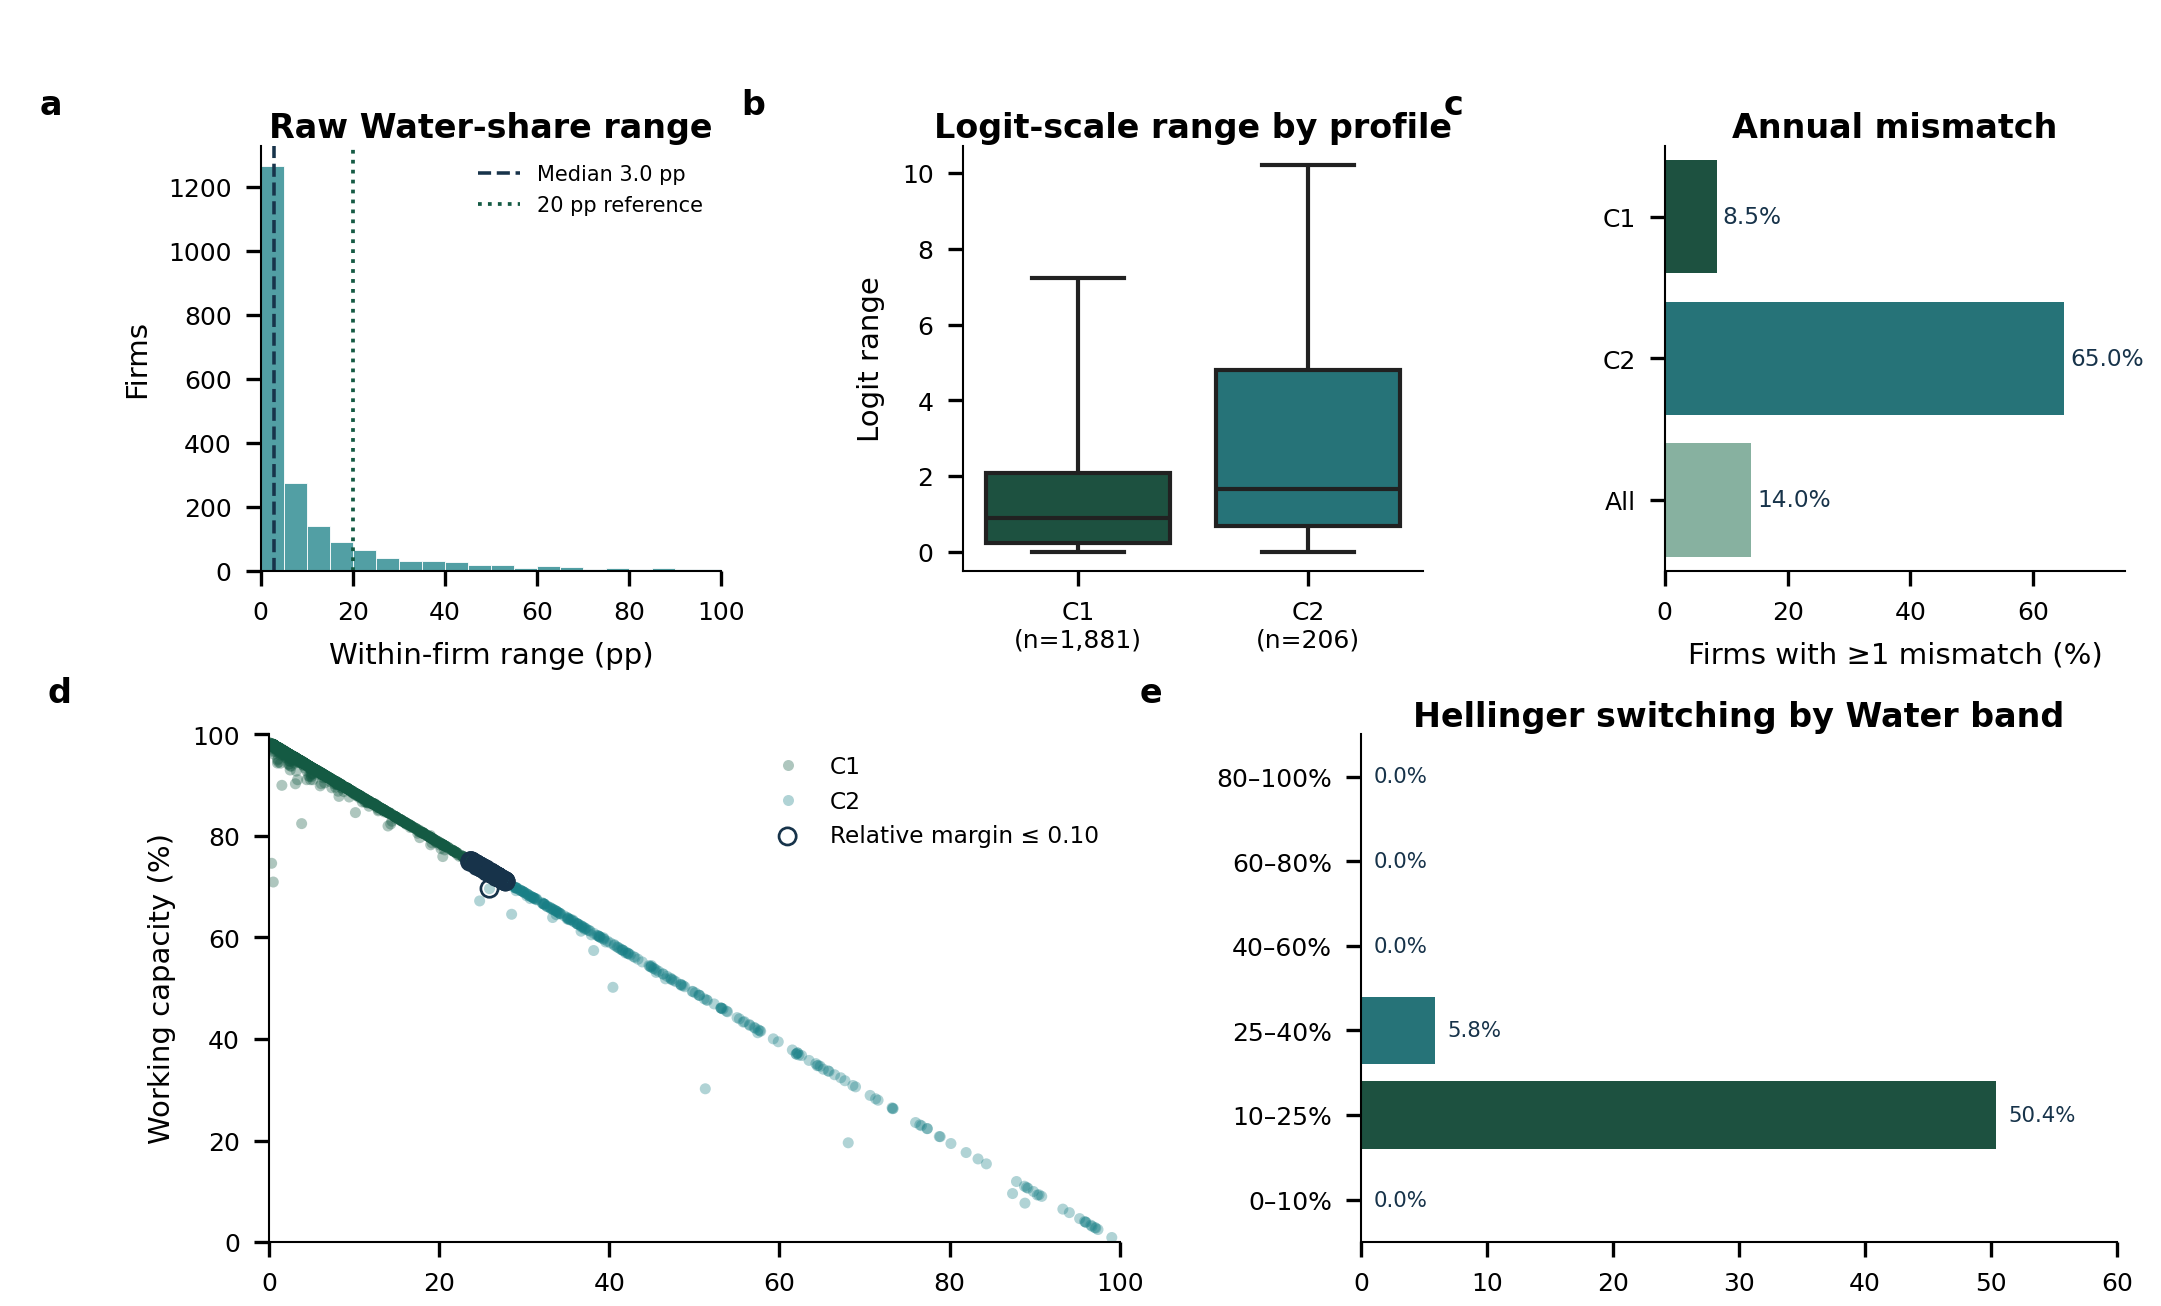

In [ ]:
# Figure 4. Within-firm temporal variation and assignment sensitivity.
temporal_hist_edges = np.arange(0, 105, 5)
temporal_hist_median = float(multi_firms["water_range_pp"].median())

temporal_plot = multi_firms[["cluster_id", "water_logit_range"]].copy()
temporal_plot["Profile"] = temporal_plot["cluster_id"].map({1: "C1", 2: "C2"})
temporal_palette = {"C1": COLORS["forest"], "C2": COLORS["teal"]}

mismatch_plot = temporal_table.copy()
mismatch_plot["Group"] = mismatch_plot["Profile"].map({
    "C1: Working-capacity dominant": "C1",
    "C2: Water-heavy (relative)": "C2",
    "All multi-year firms": "All"
})
mismatch_plot["Mismatch rate (%)"] = (
    mismatch_plot["Firms with ≥1 annual mismatch"] * 100
)
mismatch_order = ["C1", "C2", "All"]
mismatch_palette = {
    "C1": COLORS["forest"],
    "C2": COLORS["teal"],
    "All": COLORS["sage"]
}

boundary_plot = boundary.copy()
boundary_plot["Profile"] = boundary_plot["cluster_id"].map({1: "C1", 2: "C2"})
boundary_plot["Water share (%)"] = boundary_plot["water_share"] * 100
boundary_plot["Working-capacity share (%)"] = boundary_plot["working_share"] * 100

band_plot = band_summary.copy()
band_plot["Switch rate (%)"] = band_plot["Switch_rate"] * 100
band_order = water_band_labels[::-1]
band_palette = {
    "0–10%": COLORS["sage"],
    "10–25%": COLORS["forest"],
    "25–40%": COLORS["teal"],
    "40–60%": COLORS["sage"],
    "60–80%": COLORS["sage"],
    "80–100%": COLORS["sage"]
}

mp4 = cns.multipanel(max_width=183, unit="mm")

# Panel a: distribution of within-firm raw Water-share ranges.
ax4a = add_cns_panel(mp4, "a", 39, 36)
cns.histplot(
    data=multi_firms,
    x="water_range_pp",
    bins=temporal_hist_edges,
    color=COLORS["teal"],
    edgecolor="white",
    linewidth=0.2,
    ax=ax4a
)
ax4a.axvline(temporal_hist_median, color=COLORS["navy"], linestyle="--",
             linewidth=0.85, label=f"Median {temporal_hist_median:.1f} pp")
ax4a.axvline(TEMPORAL_CHANGE_PP, color=COLORS["forest"], linestyle=":",
             linewidth=0.9, label=f"{TEMPORAL_CHANGE_PP} pp reference")
ax4a.set_xlim(0, 100)
ax4a.set_title("Raw Water-share range", pad=2)
ax4a.set_xlabel("Within-firm range (pp)")
ax4a.set_ylabel("Firms")
ax4a.legend(frameon=False, fontsize=5.0, loc="upper right")

# Panel b: logit-scale range by profile; whiskers span the observed minimum and maximum.
ax4b = add_cns_panel(mp4, "b", 39, 36)
cns.boxplot(
    data=temporal_plot,
    x="Profile",
    y="water_logit_range",
    order=["C1", "C2"],
    hue="Profile",
    hue_order=["C1", "C2"],
    palette=temporal_palette,
    dodge=False,
    legend=False,
    whis=(0, 100),
    add_count=True,
    showoutliers=False,
    ax=ax4b
)
ax4b.set_title("Logit-scale range by profile", pad=2)
ax4b.set_xlabel("")
ax4b.set_ylabel("Logit range")
ax4b.tick_params(axis="x", labelsize=6)

# Panel c: percentage of multi-year firms with at least one annual mismatch.
ax4c = add_cns_panel(mp4, "c", 39, 36)
cns.barplot(
    data=mismatch_plot,
    x="Mismatch rate (%)",
    y="Group",
    order=mismatch_order,
    hue="Group",
    hue_order=mismatch_order,
    palette=mismatch_palette,
    dodge=False,
    legend=False,
    errorbar=None,
    ax=ax4c
)
ax4c.set_title("Annual mismatch", pad=2)
ax4c.set_xlabel("Firms with ≥1 mismatch (%)")
ax4c.set_ylabel("")
ax4c.set_xlim(0, 75)
for patch, (_, row) in zip(ax4c.patches, mismatch_plot.set_index("Group").loc[mismatch_order].iterrows()):
    ax4c.text(
        patch.get_width() + 1.0,
        patch.get_y() + patch.get_height() / 2,
        f'{row["Mismatch rate (%)"]:.1f}%',
        va="center", fontsize=5.6, color=COLORS["navy"]
    )

# Panel d: original-space Water versus Working-capacity projection.
ax4d = add_cns_panel(mp4, "d", 72, 43)
cns.scatterplot(
    data=boundary_plot,
    x="Water share (%)",
    y="Working-capacity share (%)",
    hue="Profile",
    hue_order=["C1", "C2"],
    palette=temporal_palette,
    s=7,
    alpha=0.34,
    linewidth=0,
    ax=ax4d
)
near = boundary_plot[boundary_plot["near_boundary"]]
ax4d.scatter(
    near["Water share (%)"],
    near["Working-capacity share (%)"],
    s=17,
    facecolors="none",
    edgecolors=COLORS["navy"],
    linewidths=0.65,
    label="Relative margin ≤ 0.10",
    zorder=5
)
ax4d.set_xlim(0, 100)
ax4d.set_ylim(0, 100)
ax4d.set_xlabel("Water share (%)")
ax4d.set_ylabel("Working capacity (%)")
ax4d.legend(frameon=False, fontsize=5.6, loc="upper right", markerscale=1.0)

# Panel e: Hellinger switch rate by original Water-share band.
ax4e = add_cns_panel(mp4, "e", 64, 43)
cns.barplot(
    data=band_plot,
    x="Switch rate (%)",
    y="Original Water-share band",
    order=band_order,
    hue="Original Water-share band",
    hue_order=band_order,
    palette=band_palette,
    dodge=False,
    legend=False,
    errorbar=None,
    ax=ax4e
)
ax4e.set_title("Hellinger switching by Water band", pad=2)
ax4e.set_xlabel("Firms switching (%)")
ax4e.set_ylabel("")
ax4e.set_xlim(0, 60)
band_rows_for_labels = band_plot.set_index("Original Water-share band").loc[band_order]
for patch, (_, row) in zip(ax4e.patches, band_rows_for_labels.iterrows()):
    ax4e.text(
        max(patch.get_width(), 0) + 1.0,
        patch.get_y() + patch.get_height() / 2,
        f'{row["Switch rate (%)"]:.1f}%',
        va="center", fontsize=5.1, color=COLORS["navy"]
    )

fig4 = ax4a.figure
export_cns_figure(fig4, "figure4_temporal_and_sensitivity")

**Figure 4 | Within-firm variation is greater in C2, while Hellinger switching is concentrated in the 10–25% Water-share band.** a, Distribution of within-firm Water-share ranges among firms with at least two observed years; dashed lines show the median and 20-percentage-point reference. b, Logit-scale ranges by profile (boxes, P25–P75; centre line, median; whiskers, observed minimum and maximum). c, Firms with at least one annual assignment mismatch under the fixed k = 2 centroids. d, Water versus Working-capacity shares for all firms; outlined points have a relative distance margin ≤0.10. e, Hellinger switch rate by original Water-share band; exact band counts are reported separately in Table 20. Annual assignments use the fixed firm-level centroids.

**Results.** C2 has a much larger raw Water-share range than C1, but the relative range-to-mean is similar (.90 versus .83). C2 firms are more likely to have at least one observed year assigned to the other fixed centroid (65.0% versus 8.5%). This is consistent with C2 being a broader group closer to the profile boundary; it should not be described as proof that C2 firms are intrinsically more unstable.

**Results.** Only 53 firms (2.1%) have a relative distance margin ≤ .10 under the original k = 2 geometry. Hellinger changes 198 firms (8.0%), with switching concentrated in the original 10% to 25% Water-share band: 189 of 375 firms in that band switch (50.4%), accounting for 95.5% of all switchers. The two percentages measure different things: closeness to the original boundary versus sensitivity to a changed distance geometry.

## 13. Overall interpretation and limitations

**What the analysis supports**

- The selected k = 2 solution is a useful **broad descriptive segmentation** of the eight absolute-impact shares.
- C1 is strongly Working-capacity dominant. C2 has a much larger Water share, but it is heterogeneous and should not be treated as one uniform company type.
- Under the raw-share Euclidean K-Means geometry, the separation is almost entirely associated with Working capacity and Water. This is a property of this representation, not evidence that the other six safeguards are unimportant in environmental terms.
- Industry is associated with profile membership, but the association is small to moderate after bias correction. Some industries are over- or under-represented in C2; this is not a causal effect.
- The main partition is stable under firm resampling, but it is sensitive to alternative compositional representations, especially CLR and Hellinger.

**Main limitations**

1. **Sign removal:** absolute values discard whether a signed component is positive or negative. The profiles describe magnitudes only.
2. **Compositional geometry:** the eight shares sum to one. Raw Euclidean K-Means is exploratory, and CLR sensitivity shows that profile membership depends on representation and zero replacement.
3. **Choice of k:** thresholds were selected after inspecting the results. Ward agreement is not independent validation, and the Ward cutoff influences which secondary k values pass.
4. **Industry imputation:** some firm-level impacts are estimated using industry-level information. This can mechanically strengthen industry-profile association. The low-imputation check reduces but does not eliminate this concern.
5. **Sparse industry table:** 41 of 112 expected industry-profile counts are below five. Permutation and exact tests are used, but sector-level dependence may still make p-values optimistic.
6. **Temporal interpretation:** annual labels are projections onto fixed firm-level centroids, not independently fitted yearly clusters. Some firms have only one observed year.
7. **Coverage:** the supplied cleaned workbook has 14,015 rows, 20 fewer than the 14,035 in the project context. The difference is unresolved without the raw file or cleaning log. Findings describe the 2010 to 2019 sample only.

All shares are firm-weighted compositions of absolute monetary impact magnitudes. They are not total environmental costs, net impacts, emissions, or measures of causal performance.

In [ ]:
# Compact, data-driven summary for report drafting.
water_band_10_25 = band_summary.loc[
    band_summary["Original Water-share band"] == "10–25%"
].iloc[0]

switchers_in_band = int(water_band_10_25["Switched"])
switch_rate_in_band = float(water_band_10_25["Switch_rate"])

summary_lines = [
    (
        f"Main solution: k={MAIN_K}; "
        f"Silhouette={selection.loc[selection.k == MAIN_K, 'Silhouette'].iloc[0]:.3f}; "
        f"worst-cluster bootstrap Jaccard="
        f"{validation.loc[validation.k == MAIN_K, 'Worst-cluster Jaccard'].iloc[0]:.3f}; "
        f"Ward ARI={validation.loc[validation.k == MAIN_K, 'ARI vs Ward'].iloc[0]:.3f}."
    ),
    (
        f"Profiles: C1={int(profile.loc[profile.cluster_id == 1, 'n_firms'].iloc[0]):,} firms "
        f"({profile.loc[profile.cluster_id == 1, 'firm_pct'].iloc[0]:.1f}%); "
        f"C2={int(profile.loc[profile.cluster_id == 2, 'n_firms'].iloc[0]):,} firms "
        f"({profile.loc[profile.cluster_id == 2, 'firm_pct'].iloc[0]:.1f}%)."
    ),
    (
        f"Composition: Working capacity + Water average "
        f"{working_water.mean():.2f}% of absolute impact; "
        f"these two subjects account for "
        f"{centroid_gap.loc[centroid_gap.Safeguard.isin(['Working capacity','Water']), 'Share of squared centroid gap (%)'].sum():.2f}% "
        "of the raw k=2 squared centroid gap."
    ),
    (
        f"Industry: {len(industry_tests)} unique Fisher tests; "
        f"{int(industry_tests['FDR significant'].sum())} pass BH-FDR q<.05; "
        f"bias-corrected Cramer's V={cramers_v_corrected:.3f}; "
        f"permutation p={permutation_p:.4g}."
    ),
    (
        f"Robustness: bootstrap mean ARI={np.mean(boot_aris):.3f}; "
        f"Hellinger ARI={ari_hellinger:.3f}; "
        f"CLR ARIs={', '.join(f'{x:.3f}' for x in clr_sensitivity['ARI vs raw-share k=2'])}."
    ),
    (
        f"Temporal: C2 firms with at least one annual fixed-centroid mismatch="
        f"{temporal_table.loc[temporal_table.Profile.str.startswith('C2'), 'Firms with ≥1 annual mismatch'].iloc[0]:.1%}; "
        f"overall firms within .10 of the main boundary="
        f"{boundary.near_boundary.mean():.1%}."
    ),
    (
        f"Hellinger switching: {switch_count:,}/{len(change):,} firms "
        f"({switch_rate:.1%}); {switchers_in_band:,} of {switch_count:,} switchers "
        f"({switchers_in_band/switch_count:.1%}) fall in the 10–25% Water band; "
        f"the switch rate within that band is {switch_rate_in_band:.1%}."
    )
]

for line in summary_lines:
    display(Markdown("- " + line))

- Main solution: k=2; Silhouette=0.795; worst-cluster bootstrap Jaccard=0.949; Ward ARI=1.000.

- Profiles: C1=2,202 firms (88.6%); C2=283 firms (11.4%).

- Composition: Working capacity + Water average 98.37% of absolute impact; these two subjects account for 99.99% of the raw k=2 squared centroid gap.

- Industry: 56 unique Fisher tests; 5 pass BH-FDR q<.05; bias-corrected Cramer's V=0.241; permutation p=9.999e-05.

- Robustness: bootstrap mean ARI=0.961; Hellinger ARI=0.622; CLR ARIs=-0.002, 0.154, 0.163.

- Temporal: C2 firms with at least one annual fixed-centroid mismatch=65.0%; overall firms within .10 of the main boundary=2.1%.

- Hellinger switching: 198/2,485 firms (8.0%); 189 of 198 switchers (95.5%) fall in the 10–25% Water band; the switch rate within that band is 50.4%.

## 14. Reporting guide

- Describe k = 2 as the **selected broad segmentation under the stated screening rule**, not as proof of two natural populations.
- Describe C2 as **Water-heavy relative to C1**, not as uniformly Water-dominant. Its Water-share distribution is wide.
- Say that Working capacity and Water dominate the raw-share Euclidean separation. Do not claim that the six other safeguards have no environmental importance.
- Treat the PCA correlations near ±1 as a consequence of the compositional constraint and dominance of two shares, not as an independent discovery.
- Report the CLR and Hellinger results as evidence of representation sensitivity. Do not present seed ARI = 1.000 as proof of robustness.
- For industry, distinguish counts from lift. Report the 56 unique Fisher tests and BH-FDR results, plus the global permutation test and bias-corrected Cramér's V.
- Use association language only. Industry does not cause cluster membership based on this analysis.
- For temporal results, say C2 firms are more likely to have annual compositions assigned to the other fixed centroid. Do not describe C2 as intrinsically unstable.

## References for methods

Aitchison, J. (1982). The statistical analysis of compositional data. *Journal of the Royal Statistical Society: Series B (Methodological), 44*(2), 139–160. https://doi.org/10.1111/j.2517-6161.1982.tb01195.x

Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x

Bergsma, W. (2013). A bias-correction for Cramér's V and Tschuprow's T. *Journal of the Korean Statistical Society, 42*(3), 323–328. https://doi.org/10.1016/j.jkss.2012.10.002

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845

Rashidi, F. (2026). *cnsplots: Publication-ready scientific plots* (Version 0.8.0). https://github.com/faridrashidi/cnsplots